In [2]:
import omnipath as op
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

/new-stg/home/alex/miniconda3/envs/omnipath/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
sig = op.interactions.OmniPath.get(genesymbols=1, directed=1, signed=1, organisms='human')
sig_big = op.interactions.PostTranslational.get(genesymbols=1, directed=1, signed=1, organisms='human')
dor_ab = op.interactions.Dorothea.get(genesymbols=1, dorothea_levels=['A','B'], organisms='human')
roles = op.requests.Intercell.get(scope='generic', genesymbols=1)  # or use generic_categories=['ligand','receptor']

In [4]:
tf_all = op.interactions.Transcriptional.get(genesymbols=1, organisms='human')
omnipath_tfs = set(tf_all['source_genesymbol'].unique())
hs_tfs = set(pd.read_csv('/new-stg/home/alex/ref/gene_sets/hs_tfs.txt', header=None).iloc[:,0].values)

print(len(hs_tfs))
print(len(omnipath_tfs))

def build_overlap_with_complexes(hs_tfs, omnipath_tfs, sep="_"):
    # normalize a bit (strip/uppercase) so minor formatting differences don’t block overlaps
    hs = {s.strip().upper() for s in hs_tfs if isinstance(s, str)}
    op = {s.strip().upper() for s in omnipath_tfs if isinstance(s, str)}

    # plain overlap (single-gene TFs that literally exist in both sets)
    singles_overlap = hs & op

    # complexes in OmniPath: anything containing the separator (default "_")
    complex_strings = {s for s in op if sep in s}

    complex_ok = set()         # complex strings to include in the overlap_tfs
    complex_components = set() # the component TF symbols from passing complexes

    for cx in complex_strings:
        parts = [p for p in cx.split(sep) if p]  # supports >2 members as well
        # include the complex if *all* components are present in hs_tfs
        if all(p in hs for p in parts):
            complex_ok.add(cx)
            complex_components.update(parts)

    # final set you asked for: all single-TF overlaps *plus* any complexes that pass the check
    overlap_tfs = singles_overlap | complex_ok

    # (optional) return helpful breakdowns too
    return {
        "overlap_tfs": overlap_tfs,                         # singles + qualifying complexes
        "singles_overlap": singles_overlap,                 # only singletons in both
        "complexes_included": complex_ok,                   # complex strings admitted
        "components_from_included_complexes": complex_components
    }

# --- example usage ---
res = build_overlap_with_complexes(hs_tfs, omnipath_tfs)
overlap_tfs = res["overlap_tfs"]

print(f"{len(res['singles_overlap'])} single-TFs overlap")
print(f"{len(res['complexes_included'])} complexes included")
print(f"{len(overlap_tfs)} total entries in overlap_tfs")
# If you want just the component TFs back (no complex strings):
just_components = (res["singles_overlap"] | res["components_from_included_complexes"])

1639
1472
941 single-TFs overlap
60 complexes included
1001 total entries in overlap_tfs


In [5]:
def unique_sources(df, col="sources", sep=";"):
    s = (df[col]
         .dropna()
         .astype(str)
         .str.split(sep)
         .explode()
         .str.strip())
    s = s[s.ne("")]            # drop empty tokens
    return set(s.unique()), s  # (unique set, long Series if you want counts)


unique_srcs, src_long = unique_sources(sig, "sources")

In [6]:
drop = {'NetPath', 'Wang', 'InnateDB', 'KEGG-MEDICUS', 'SPIKE', 'SPIKE_LC', 'Lit-BM-17', 'HINT', 'HPRD', 'Macrophage'}
keep = unique_srcs - drop

sig_subset = sig[sig['is_directed'] == True].copy()
sig_subset = sig_subset[sig_subset['source'] != sig_subset['target']]
sig_subset = sig_subset[sig_subset['sources'].str.contains('|'.join(keep))]
sig_subset = sig_subset[sig_subset['n_sources'] >= 1]

In [7]:
lr_df = pd.read_csv('/new-stg/home/alex/ref/cellchatdb/hs/interaction_input_CellChatDB.csv', index_col=0)
lr_df[lr_df['ligand'] == 'TNF']

,interaction_name,pathway_name,ligand,receptor,agonist,antagonist,co_A_receptor,co_I_receptor,evidence,annotation,interaction_name_2
TNF_TNFRSF1A,TNF_TNFRSF1A,TNF,TNF,TNFRSF1A,NaN,NaN,NaN,NaN,KEGG: hsa04060,Secreted Signaling,TNF - TNFRSF1A
TNF_TNFRSF1B,TNF_TNFRSF1B,TNF,TNF,TNFRSF1B,NaN,NaN,NaN,NaN,KEGG: hsa04060,Secreted Signaling,TNF - TNFRSF1B


In [8]:
G = op.interactions.PostTranslational.graph(sig_subset)  # networkx.DiGraph
print(G)

assert G.has_edge('TNF','TNFRSF1A') or G.has_edge('TNF','TNFRSF1B')
sig_subset[sig_subset['source_genesymbol'] == 'TNFRSF1A']

DiGraph with 6749 nodes and 69456 edges


,source,target,source_genesymbol,target_genesymbol,is_directed,is_stimulation,is_inhibition,consensus_direction,consensus_stimulation,consensus_inhibition,curation_effort,references,sources,n_sources,n_primary_sources,n_references,references_stripped
4230,P19438,Q13546,TNFRSF1A,RIPK1,True,True,False,True,True,False,74,BioGRID:11002422;BioGRID:18621737;BioGRID:1872...,BioGRID;CancerCellMap;Cui2007;DIP;HINT;HPRD;In...,13,12,50,10356400;10744744;10755617;10795740;11002422;1...
4231,P19438,Q15628,TNFRSF1A,TRADD,True,True,False,True,True,False,93,CancerCellMap:10634209;CancerCellMap:12887920;...,CancerCellMap;Cui2007;DIP;DOMINO;HINT;HPRD;Inn...,16,15,47,10187805;10634209;10795740;11035039;11502070;1...
4792,P19438,Q12933,TNFRSF1A,TRAF2,True,True,False,True,True,False,41,CancerCellMap:12887920;HINT:10795740;HINT:1272...,CancerCellMap;Cui2007;HINT;HPRD;InnateDB;IntAc...,14,12,27,10795740;11821416;12721308;12887920;15115707;1...


In [258]:
# ============================================================
# Explode compound nodes (e.g., NFKB1_RELA) -> NFKB1 and RELA
#   - Works from your sig_subset (edge table) and rebuilds a new G
#   - Collapses duplicate edges with robust sign merge rules
#   - NEW: "prefer original TF sign" override:
#       If an edge (u->TF) existed in the ORIGINAL sig_subset with an unambiguous sign,
#       then after splitting/merging we FORCE the same sign for (u->TF), even if
#       splitting introduced contradictory evidence via complexes.
# ============================================================

import re
import numpy as np
import pandas as pd
import networkx as nx

_SPLIT_SEP = "_"
KNOWN_GENE_SYMBOLS = None  # set(...) or None

def _is_valid_symbol(s: str) -> bool:
    return bool(re.fullmatch(r"[A-Z0-9]+", s))

def explode_symbol(sym: str, sep=_SPLIT_SEP, known_symbols=None, only_two_parts=True):
    if not isinstance(sym, str):
        return [sym]
    if sep not in sym:
        return [sym]
    parts = sym.split(sep)
    if only_two_parts and len(parts) != 2:
        return [sym]
    a, b = parts[0].strip(), parts[1].strip()
    if not a or not b:
        return [sym]
    if not (_is_valid_symbol(a) and _is_valid_symbol(b)):
        return [sym]
    if known_symbols is not None:
        if (a not in known_symbols) or (b not in known_symbols):
            return [sym]
    return [a, b]

def explode_edges(sig_subset: pd.DataFrame,
                 src_col="source_genesymbol",
                 tgt_col="target_genesymbol",
                 known_symbols=None,
                 only_two_parts=True):
    req = {src_col, tgt_col}
    missing = [c for c in req if c not in sig_subset.columns]
    if missing:
        raise ValueError(f"sig_subset missing columns: {missing}")

    rows = []
    for _, r in sig_subset.iterrows():
        us = explode_symbol(r[src_col], known_symbols=known_symbols, only_two_parts=only_two_parts)
        vs = explode_symbol(r[tgt_col], known_symbols=known_symbols, only_two_parts=only_two_parts)
        for u in us:
            for v in vs:
                if u == v:
                    continue
                rr = r.to_dict()
                rr["u"] = str(u)
                rr["v"] = str(v)
                rows.append(rr)

    out = pd.DataFrame(rows)
    out = out.dropna(subset=["u", "v"])
    out = out[out["u"] != out["v"]].copy()
    return out

def _merge_sources(series):
    vals = []
    for x in series.dropna().tolist():
        if isinstance(x, (list, tuple, set)):
            vals.extend(list(x))
        elif isinstance(x, str):
            if "|" in x:
                vals.extend([t for t in x.split("|") if t])
            elif ";" in x:
                vals.extend([t for t in x.split(";") if t])
            else:
                vals.append(x)
        else:
            vals.append(str(x))
    vals = sorted(set([v.strip() for v in vals if v and str(v).strip()]))
    return "|".join(vals) if vals else np.nan

def _merge_refs(series):
    vals = []
    for x in series.dropna().tolist():
        if isinstance(x, str):
            if ";" in x:
                vals.extend([t for t in x.split(";") if t])
            elif "|" in x:
                vals.extend([t for t in x.split("|") if t])
            else:
                vals.append(x)
        else:
            vals.append(str(x))
    vals = sorted(set([v.strip() for v in vals if v and str(v).strip()]))
    return ";".join(vals) if vals else np.nan

def build_original_edge_sign_map(sig_subset: pd.DataFrame,
                                 tfs,
                                 src_col="source_genesymbol",
                                 tgt_col="target_genesymbol"):
    """
    Return dict mapping (u, tf) -> (stim_bool, inhib_bool, is_unambiguous).
    Only for edges where target is a TF in `tfs`, and only if the original sign is unambiguous.
    """
    df0 = sig_subset.copy()

    # normalize booleans
    for col in ["is_stimulation", "is_inhibition"]:
        if col in df0.columns:
            df0[col] = df0[col].fillna(False).astype(bool)
        else:
            df0[col] = False

    df0["u0"] = df0[src_col].astype(str)
    df0["v0"] = df0[tgt_col].astype(str)
    tfset = set(map(str, tfs))

    df0 = df0[df0["v0"].isin(tfset)].copy()
    if df0.empty:
        return {}

    # collapse duplicates (u0,v0) in the original table (any stim, any inhib)
    df0m = (df0.groupby(["u0", "v0"], as_index=False)
              .agg({"is_stimulation": "any", "is_inhibition": "any"}))

    # keep only unambiguous signed edges (exactly one of stim/inhib)
    unamb = df0m[(df0m["is_stimulation"] ^ df0m["is_inhibition"])].copy()

    sign_map = {}
    for _, r in unamb.iterrows():
        sign_map[(r["u0"], r["v0"])] = (bool(r["is_stimulation"]), bool(r["is_inhibition"]), True)
    return sign_map

def merge_duplicate_edges(df_expanded: pd.DataFrame, *, prefer_sign_map=None):
    """
    Collapse duplicates (u,v). Merge sign evidence and metadata.

    Base merge:
      - stim_any = any(is_stimulation)
      - inhib_any = any(is_inhibition)
      - ambiguous if both True

    NEW override:
      - If prefer_sign_map contains an unambiguous original sign for (u,v),
        force (stim,inhib) to that original sign.
    """
    df = df_expanded.copy()

    for col in ["is_stimulation", "is_inhibition"]:
        if col in df.columns:
            df[col] = df[col].fillna(False).astype(bool)
        else:
            df[col] = False

    agg_dict = {
        "is_stimulation": "any",
        "is_inhibition": "any",
    }
    if "curation_effort" in df.columns:
        agg_dict["curation_effort"] = "max"
    if "sources" in df.columns:
        agg_dict["sources"] = _merge_sources
    if "references" in df.columns:
        agg_dict["references"] = _merge_refs

    dfm = (df.groupby(["u", "v"], as_index=False)
             .agg(agg_dict))

    # ---- Prefer-original-TF-sign override ----
    if prefer_sign_map:
        # vectorized apply via merge (faster/cleaner than row-wise apply)
        pref = pd.DataFrame(
            [(u, v, stim, inhib) for (u, v), (stim, inhib, ok) in prefer_sign_map.items() if ok],
            columns=["u", "v", "_pref_stim", "_pref_inhib"]
        )
        if not pref.empty:
            dfm = dfm.merge(pref, on=["u", "v"], how="left")

            mask = dfm["_pref_stim"].notna() & dfm["_pref_inhib"].notna()
            # force sign where preference exists
            dfm.loc[mask, "is_stimulation"] = dfm.loc[mask, "_pref_stim"].astype(bool)
            dfm.loc[mask, "is_inhibition"]  = dfm.loc[mask, "_pref_inhib"].astype(bool)

            dfm = dfm.drop(columns=["_pref_stim", "_pref_inhib"])

    dfm["unsigned_for_diffusion"] = dfm["is_stimulation"] & dfm["is_inhibition"]
    return dfm

def build_digraph_from_merged(dfm: pd.DataFrame):
    G2 = nx.DiGraph()
    for _, r in dfm.iterrows():
        u, v = r["u"], r["v"]
        attrs = {k: r[k] for k in dfm.columns if k not in ("u", "v")}
        G2.add_edge(u, v, **attrs)
    return G2

def explode_tf_set(tfs, known_symbols=None):
    out = set()
    for tf in tfs:
        for t in explode_symbol(tf, known_symbols=known_symbols, only_two_parts=True):
            out.add(t)
    return out

# ============================================================
# RUN: build new graph and updated TF list
# ============================================================

# 0) Define "base TFs" (the ones you care about preserving sign for)
#    Here: all TF symbols that are NOT compounds after your explode rules.
base_tfs = set()
for tf in overlap_tfs:
    parts = explode_symbol(tf, known_symbols=KNOWN_GENE_SYMBOLS, only_two_parts=True)
    # if it doesn't explode, it's a base TF symbol; keep it
    if len(parts) == 1 and str(parts[0]) == str(tf):
        base_tfs.add(str(tf))

# 1) Build preference map from ORIGINAL sig_subset
prefer_sign_map = build_original_edge_sign_map(
    sig_subset,
    tfs=base_tfs,
    src_col="source_genesymbol",
    tgt_col="target_genesymbol",
)

# 2) Expand edge table (splitting X_Y -> X and Y)
sig_exp = explode_edges(
    sig_subset,
    src_col="source_genesymbol",
    tgt_col="target_genesymbol",
    known_symbols=KNOWN_GENE_SYMBOLS,
    only_two_parts=True,
)

# 3) Collapse duplicates + apply prefer_sign_map override
sig_merged = merge_duplicate_edges(sig_exp, prefer_sign_map=prefer_sign_map)

# 4) Build graph
G_split = build_digraph_from_merged(sig_merged)

print("Original:", G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")
print("Split   :", G_split.number_of_nodes(), "nodes,", G_split.number_of_edges(), "edges")
print("Ambiguous (stim & inhib) edges:", int(sig_merged["unsigned_for_diffusion"].sum()))
print("Prefer-sign map size (unambiguous original u->TF edges):", len(prefer_sign_map))

# 5) Update TF set: explode TF names the same way and keep only those present in graph
overlap_tfs_split = sorted(explode_tf_set(overlap_tfs, known_symbols=KNOWN_GENE_SYMBOLS) & set(G_split.nodes()))
print("TFs in original overlap_tfs:", len(overlap_tfs))
print("TFs after split & intersect:", len(overlap_tfs_split))

# Sanity: check RELA/NFKB1/complex presence
for k in ["RELA", "NFKB1", "NFKB1_RELA", "RELA_NFKB1"]:
    print(k, "in G_split?", k in G_split)

# ------------------------------------------------------------
# You should now run diffusion on G_split and overlap_tfs_split
# ------------------------------------------------------------

Original: 6749 nodes, 69456 edges
Split   : 6426 nodes, 34376 edges
Ambiguous (stim & inhib) edges: 1315
Prefer-sign map size (unambiguous original u->TF edges): 3919
TFs in original overlap_tfs: 1001
TFs after split & intersect: 501
RELA in G_split? True
NFKB1 in G_split? True
NFKB1_RELA in G_split? False
RELA_NFKB1 in G_split? False


# Ligand-first & general approach

In [84]:
from collections import defaultdict
import networkx as nx
import pandas as pd

# ---------- utilities ----------
def _edge_sign(d: dict) -> int:
    """+1 for stimulation, -1 for inhibition, 0 if unknown/neutral."""
    if d.get('is_stimulation'): return +1
    if d.get('is_inhibition'):  return -1
    return 0

def _build_lr_graph(lr_df: pd.DataFrame,
                    ligand_col: str = 'ligand',
                    receptor_col: str = 'receptor',
                    normalize: bool = True) -> nx.DiGraph:
    """
    Build a directed LR graph (ligand -> receptor) from a CellChat/CellTalkDB-like table.
    """
    LR_G = nx.DiGraph()
    if lr_df is None or len(lr_df) == 0:
        return LR_G

    df = lr_df[[ligand_col, receptor_col]].dropna().copy()
    if normalize:
        # strip whitespace; keep case as-is (assumes symbols match G)
        df[ligand_col]  = df[ligand_col].astype(str).str.strip()
        df[receptor_col]= df[receptor_col].astype(str).str.strip()

    for lig, rec in df.itertuples(index=False, name=None):
        if lig and rec:
            LR_G.add_edge(lig, rec)  # no sign info here
    return LR_G

# ---------- multiplex traversal ----------
def build_radius_tree_and_tf_maps_multiplex(
    G: nx.DiGraph,
    source: str,
    tfs: set = frozenset(),
    radius: int = 6,
    stop_at_tf: bool = True,
    is_ligand: bool = False,
    lr_df: pd.DataFrame | None = None,
    ligand_col: str = 'ligand',
    receptor_col: str = 'receptor',
    lr_edge_sign: int = +1,
    restrict_lr_to_nodes_in_G: bool = True,
):
    """
    Depth-first expansion from `source` up to `radius` hops.
    If `is_ligand=True`, the first hop uses ligand->receptor pairs from `lr_df`,
    then switches to intracellular graph `G` for all deeper hops.

    Returns:
      - tree: dict[node] -> set(children)
      - tf_targets_by_path: dict[path_tuple_to_parent] -> set(TFs that are immediate children)
      - tf_terminal_paths:  dict[path_tuple_to_parent] -> set(TFs that are immediate children)
      - path_signs: dict[path_tuple] -> net sign along the path *to the parent*
    """
    if source is None:
        raise ValueError("`source` is required.")
    if source not in G and not is_ligand:
        raise ValueError(f"Source '{source}' not in intracellular graph `G`.")

    # Build LR graph if needed
    LR_G = _build_lr_graph(lr_df, ligand_col, receptor_col) if is_ligand else None

    # Helper to get successors for a node at a given depth
    def _successors(node: str, depth: int):
        if is_ligand and depth == 0 and LR_G is not None:
            # First hop: ligand -> receptor(s) from LR table
            nbrs = list(LR_G.successors(node))
            if restrict_lr_to_nodes_in_G:
                nbrs = [n for n in nbrs if n in G]  # ensure continuation possible
            return nbrs
        # Subsequent hops: use intracellular graph
        return list(G.successors(node))

    # Helper to get edge sign (first hop from LR assumed lr_edge_sign)
    def _succ_edge_sign(u: str, v: str, depth: int) -> int:
        if is_ligand and depth == 0 and LR_G is not None and LR_G.has_edge(u, v):
            return lr_edge_sign  # no sign in LR table; treat as +1 by default
        # Otherwise pull from G
        return _edge_sign(G.get_edge_data(u, v, {}) or {})

    # Outputs
    tree = defaultdict(set)
    tf_targets_by_path = defaultdict(set)
    tf_terminal_paths  = defaultdict(set)
    path_signs         = {}  # sign to current node (parent of any TF child)

    # DFS
    def dfs(node: str, depth: int, path: tuple[str, ...], net_sign: int):
        path_signs[path] = net_sign

        # record TF children (as children of the current node)
        tf_children = []
        for nbr in _successors(node, depth):
            if nbr in path:
                continue
            if nbr in tfs:
                tf_children.append(nbr)
        if tf_children:
            tf_targets_by_path[path].update(tf_children)
            tf_terminal_paths[path].update(tf_children)
            # net sign to parent already recorded in path_signs[path]

        if depth == radius:
            return

        # expand non-TF children
        for nbr in _successors(node, depth):
            if nbr in path:
                continue
            if stop_at_tf and (nbr in tfs):
                continue

            tree[node].add(nbr)
            es = _succ_edge_sign(node, nbr, depth)
            new_sign = net_sign * (es if es else 1)
            dfs(nbr, depth + 1, path + (nbr,), new_sign)

    dfs(source, 0, (source,), 1)
    return tree, tf_targets_by_path, tf_terminal_paths, path_signs

# Peek at a few TF-terminal paths (as '→'-joined strings)
def fmt_path(p): 
    return " → ".join(p)

In [85]:
tree, tf_targets_by_path, tf_terminal_paths, path_signs = build_radius_tree_and_tf_maps_multiplex(
    G,
    source='TNF',
    tfs=overlap_tfs,
    radius=5,
    is_ligand=True,
    lr_df=lr_df,              # CellChat/CellTalkDB-style table
    ligand_col='ligand',
    receptor_col='receptor',
    lr_edge_sign=+1,          # treat LR hop as activating (change if needed)
    restrict_lr_to_nodes_in_G=True,
)

print(len(tree), "nodes expanded in the tree")
print(len(tf_terminal_paths), "distinct paths that end in a TF")

for i, (p, tfset) in enumerate(tf_terminal_paths.items()):
    if i == 20: break
    print(fmt_path(p), "=>", tfset, "; net_sign:", path_signs[p])

116 nodes expanded in the tree
2365 distinct paths that end in a TF
TNF → TNFRSF1A → RIPK1 → FADD → CASP10 → CASP3 => {'MEF2B'} ; net_sign: 1
TNF → TNFRSF1A → RIPK1 → FADD → CASP8 → CASP3 => {'MEF2B'} ; net_sign: 1
TNF → TNFRSF1A → RIPK1 → FADD → CASP8 → CASP8AP2 => {'NFKB1', 'NFKB1_RELA'} ; net_sign: 1
TNF → TNFRSF1A → RIPK1 → FADD → CASP8 → CASP6 => {'SATB1'} ; net_sign: 1
TNF → TNFRSF1A → RIPK1 → FADD → CASP8 → CASP7 => {'MEF2B'} ; net_sign: 1
TNF → TNFRSF1A → RIPK1 → FADD → CASP8 → MAP3K14 => {'STAT3', 'RELA', 'NFKB2'} ; net_sign: 1
TNF → TNFRSF1A → RIPK1 → FADD → CASP8 → RNF31 => {'NR0B1'} ; net_sign: -1
TNF → TNFRSF1A → RIPK1 → RIPK3 → TRIM28 => {'SETDB1', 'STAT1'} ; net_sign: -1
TNF → TNFRSF1A → RIPK1 → RIPK3 → TRIM28 → MDM2 => {'IRF1', 'OVOL2', 'TP73', 'NFATC2', 'TP63', 'AR', 'RUNX3', 'FOXO4', 'HIF1A', 'TP53', 'PPARG'} ; net_sign: -1
TNF → TNFRSF1A → RIPK1 → RIPK3 → TRIM28 → FBP1 => {'HIF1A'} ; net_sign: 1
TNF → TNFRSF1A → RIPK1 → MAP3K1 => {'STAT3'} ; net_sign: 1
TNF → TNFRSF1

In [86]:
from collections import defaultdict
import math
import pandas as pd
import numpy as np

def paths_by_tf(tf_terminal_paths, path_signs=None, as_strings=True, joiner=" → "):
    """
    Invert {path_tuple -> {TFs}} into {TF -> [paths...]}

    Returns a dict mapping each TF to a list of path records:
      {'path': <tuple or string>, 'net_sign': (+1/-1), 'length': hops}
    """
    tf2paths = defaultdict(list)

    for path, tfset in tf_terminal_paths.items():
        # represent the path either as a tuple or a pretty string
        path_repr = (joiner.join(path) if as_strings else path)
        length = len(path) - 1
        net = path_signs.get(path, 1) if path_signs is not None else None

        for tf in tfset:
            tf2paths[tf].append({'path': path_repr, 'net_sign': net, 'length': length})

    # optional: sort each TF’s paths by length then lexicographically
    for tf, lst in tf2paths.items():
        lst.sort(key=lambda r: (r['length'], r['path']))

    return dict(tf2paths)

# ---- helpers ---------------------------------------------------------------

def _length_weight(L: int, mode: str = "exp", decay: float = 0.7) -> float:
    """
    Weight shorter paths more.
    - mode="exp":  decay**(L-1)  (default; strong preference for short)
    - mode="inv":  1.0 / L       (milder)
    """
    if L <= 0:
        return 0.0
    if mode == "inv":
        return 1.0 / L
    # default: exponential
    return decay ** (L - 1)

def _normalize_path_key(p):
    """
    Ensure a hashable, comparable key. If tf_to_paths stored strings, use them;
    if tuples, join into a string. You can swap this to 'tuple(p.split(" → "))'
    if you prefer tuples internally.
    """
    return p

def _edge_sign_from_attrs(attrs: dict) -> int:
    """Map OmniPath edge attrs to {-1,0,+1}."""
    if not attrs:
        return 0
    if attrs.get("is_stimulation"):
        return +1
    if attrs.get("is_inhibition"):
        return -1
    return 0

# ---- (NEW) attach terminal (parent→TF) sign to each record -----------------
def attach_terminal_signs(tf_to_paths: dict, G, sep="→", trim=True):
    """
    For each record {'path': 'A → ... → PARENT', 'net_sign': sign_to_parent, 'length': L},
    look up the edge PARENT→TF in G and store r['terminal_sign'] in {-1,0,+1}.
    Returns a *new* dict (does not mutate the input).
    """
    out = {}
    for tf, recs in tf_to_paths.items():
        new_recs = []
        for r in recs:
            # parse parent from the path (string or tuple)
            path = r["path"]
            if isinstance(path, tuple):
                parent = path[-1]
                L = len(path) - 1
            else:
                parts = [x.strip() if trim else x for x in str(path).split(sep)]
                parent = parts[-1]
                L = len(parts) - 1

            # get last-hop sign
            attrs = (G.get_edge_data(parent, tf, {}) or {})
            last = _edge_sign_from_attrs(attrs)

            rec = dict(r)  # shallow copy
            rec["terminal_sign"] = last
            # ensure 'length' is the hops to the *parent*
            rec["length"] = L
            new_recs.append(rec)
        out[tf] = new_recs
    return out

# ---- (A) Jaccard similarity between TFs' path sets ------------------------

def jaccard_paths(tf_to_paths: dict, weighted: bool = False,
                  weight_mode: str = "exp", decay: float = 0.7) -> pd.DataFrame:
    """
    Build a |TF| x |TF| (weighted) Jaccard matrix over path keys.
    If weighted=False: classic J = |A∩B| / |A∪B|.
    If weighted=True:  Weighted Jaccard = sum min(w_i, w_j) / sum max(w_i, w_j),
                       with path weights from _length_weight(length).
    """
    # Build per-TF maps: paths -> weight (or 1.0)
    tf_paths = {}
    all_tfs = sorted(tf_to_paths.keys())
    for tf, recs in tf_to_paths.items():
        d = defaultdict(float)
        for r in recs:
            key = _normalize_path_key(r["path"])
            if weighted:
                d[key] = max(d[key], _length_weight(r["length"], weight_mode, decay))
            else:
                d[key] = 1.0
        tf_paths[tf] = d

    n = len(all_tfs)
    J = np.eye(n, dtype=float)
    for i in range(n):
        di = tf_paths[all_tfs[i]]
        for j in range(i+1, n):
            dj = tf_paths[all_tfs[j]]
            if not weighted:
                Ai, Aj = set(di.keys()), set(dj.keys())
                inter = len(Ai & Aj)
                union = len(Ai | Aj)
                val = inter / union if union else np.nan
            else:
                keys = set(di.keys()) | set(dj.keys())
                num = 0.0; den = 0.0
                for k in keys:
                    wi, wj = di.get(k, 0.0), dj.get(k, 0.0)
                    num += min(wi, wj)
                    den += max(wi, wj)
                val = (num / den) if den > 0 else np.nan
            J[i, j] = J[j, i] = val

    return pd.DataFrame(J, index=all_tfs, columns=all_tfs)

# ---- (B) Length-weighted activation/inhibition score per TF ---------------

def tf_activity_score(tf_to_paths: dict, weight_mode: str = "exp", decay: float = 0.7,
                      ignore_zero_sign: bool = True,
                      include_terminal_sign: bool = True,
                      require_last_signed: bool = True) -> pd.DataFrame:
    """
    Score in [-1, 1] for each TF:
        score = sum_i (sign_i * w(length_i)) / sum_i w(length_i)

    sign_i combines:
      - r['net_sign']  : sign to the *parent* of the TF
      - r['terminal_sign'] in {-1,0,+1} (parent→TF edge), if include_terminal_sign==True

    If require_last_signed=True, drop paths whose terminal_sign==0 (unknown).
    """
    rows = []
    for tf, recs in tf_to_paths.items():
        num = 0.0
        den = 0.0
        n_paths = 0
        min_len = math.inf
        for r in recs:
            parent_sign = r.get("net_sign", 0)
            last = r.get("terminal_sign", 0)

            if include_terminal_sign:
                if require_last_signed and last == 0:
                    continue  # skip paths without a known final sign
                s = parent_sign if last == 0 else parent_sign * last
            else:
                s = parent_sign

            if ignore_zero_sign and (s == 0 or s is None):
                continue

            w = _length_weight(r["length"], weight_mode, decay)
            num += (s or 0) * w
            den += w
            n_paths += 1
            if r["length"] < min_len:
                min_len = r["length"]
        score = (num / den) if den > 0 else 0.0
        rows.append({
            "TF": tf,
            "score": score,
            "n_paths_used": n_paths,
            "eff_weight_sum": den,
            "shortest_path_len": (min_len if min_len < math.inf else None)
        })
    df = pd.DataFrame(rows).sort_values(["score","n_paths_used"], ascending=[False, False]).reset_index(drop=True)
    return df

In [87]:
# --- build it ---
tf_to_paths = paths_by_tf(tf_terminal_paths, path_signs, as_strings=True)

# quick sanity checks
print(len(tf_to_paths), "unique TFs reached within the radius")
print("Example (RELA):")
for rec in tf_to_paths.get('RELA', [])[:10]:
    print(rec)

# quick sanity checks
print(len(tf_to_paths), "unique TFs reached within the radius")
print("Example (NFKB1):")
for rec in tf_to_paths.get('NFKB1', [])[:10]:
    print(rec)

306 unique TFs reached within the radius
Example (RELA):
{'path': 'TNF → TNFRSF1A → RIPK1 → IKBKG', 'net_sign': 1, 'length': 3}
{'path': 'TNF → TNFRSF1A → RIPK1 → TBK1', 'net_sign': 1, 'length': 3}
{'path': 'TNF → TNFRSF1A → TRAF2 → MAP3K14', 'net_sign': 1, 'length': 3}
{'path': 'TNF → TNFRSF1B → TRAF2 → MAP3K14', 'net_sign': 1, 'length': 3}
{'path': 'TNF → TNFRSF1A → RIPK1 → CASP8 → MAP3K14', 'net_sign': 1, 'length': 4}
{'path': 'TNF → TNFRSF1A → RIPK1 → CHUK_IKBKB_IKBKG → IKBKG', 'net_sign': -1, 'length': 4}
{'path': 'TNF → TNFRSF1A → RIPK1 → CHUK_IKBKB_IKBKG → NFKBIA', 'net_sign': 1, 'length': 4}
{'path': 'TNF → TNFRSF1A → RIPK1 → DAB2IP → GSK3B', 'net_sign': 1, 'length': 4}
{'path': 'TNF → TNFRSF1A → RIPK1 → IKBKG → CHUK', 'net_sign': 1, 'length': 4}
{'path': 'TNF → TNFRSF1A → RIPK1 → IKBKG → IKBKB', 'net_sign': 1, 'length': 4}
306 unique TFs reached within the radius
Example (NFKB1):
{'path': 'TNF → TNFRSF1A → RIPK1 → TBK1', 'net_sign': 1, 'length': 3}
{'path': 'TNF → TNFRSF1A → R

NFKB1         1.000000
NFKB1_RELA    0.548243
IRF5          0.432018
RELA          0.400327
NCOA3         0.359566
Name: NFKB1, dtype: float64
RELA          1.000000
NFKB1_RELA    0.580706
NFKB1         0.400327
NCOA3         0.355976
FOXO3         0.348209
Name: RELA, dtype: float64


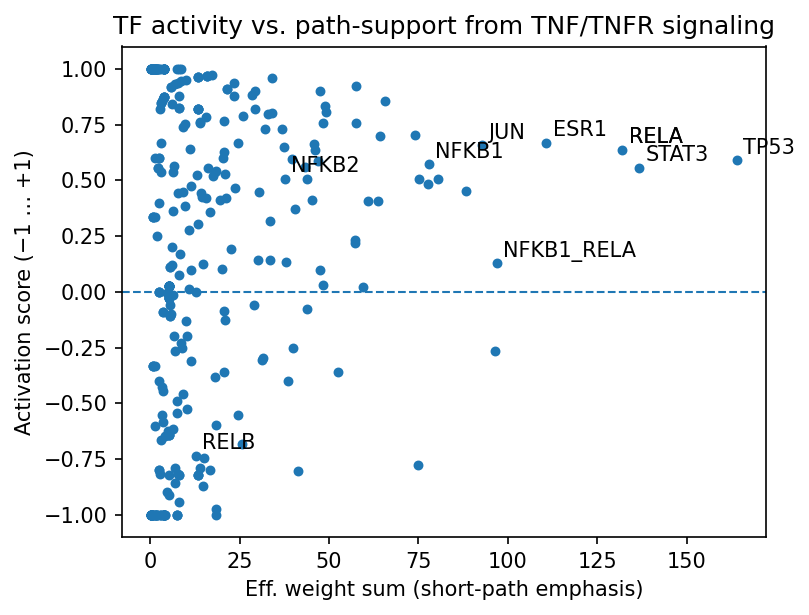

,TF,score,n_paths_used,eff_weight_sum,shortest_path_len,_rank
107,TP53,0.591742,664,163.9981,3,97.0445
100,RELA,0.637416,521,132.0599,3,84.1771
112,STAT3,0.557053,538,136.6855,3,76.1411
92,ESR1,0.668628,445,110.7547,4,74.0537
96,JUN,0.658898,372,92.7129,4,61.0883
247,NFE2L2,-0.775435,301,74.8426,4,58.0356
63,ATF2,0.853556,265,65.5816,4,55.9776
47,ELK1,0.924731,231,57.4182,4,53.0964
90,STAT1,0.702778,297,74.0880,4,52.0674
91,CREB1,0.697650,261,64.2096,4,44.7958


In [88]:
tf_to_paths_with_last = attach_terminal_signs(tf_to_paths, G, sep="→", trim=True)

# 2) Jaccards (unchanged)
J  = jaccard_paths(tf_to_paths_with_last, weighted=False)
Jw = jaccard_paths(tf_to_paths_with_last, weighted=True, weight_mode="exp", decay=0.7)

# 3) Length-weighted activation score INCLUDING terminal sign
scores = tf_activity_score(
    tf_to_paths_with_last,
    weight_mode="exp",
    decay=0.7,
    ignore_zero_sign=True,
    include_terminal_sign=True,
    require_last_signed=True     # recommended; set False to treat unknown terminal edges as neutral
)

# Top/bottom examples
top_act = scores.sort_values("score", ascending=False).head(15)
top_inh = scores.sort_values("score", ascending=True).head(15)

# (Optional) restrict to short paths first
def filter_by_length(tf_to_paths, max_len=3):
    out = {}
    for tf, recs in tf_to_paths.items():
        kept = [r for r in recs if r["length"] <= max_len]
        if kept:
            out[tf] = kept
    return out


print(Jw.loc['NFKB1',:].sort_values(ascending=False)[:5])
print(Jw.loc['RELA',:].sort_values(ascending=False)[:5])

df = scores.copy()  # columns: ['TF','score','n_paths_used','eff_weight_sum','shortest_path_len']

fig, ax = plt.subplots(figsize=(5.5, 4.2), dpi=150)
ax.scatter(df['eff_weight_sum'], df['score'], s=14)  # one dot per TF

# reference line at 0 (neutral)
ax.axhline(0, lw=1, ls='--')

ax.set_xlabel('Eff. weight sum (short-path emphasis)')
ax.set_ylabel('Activation score (−1 … +1)')
ax.set_title('TF activity vs. path-support from TNF/TNFR signaling')

df['_rank'] = df['eff_weight_sum'] * df['score'].abs()
for _, row in df.nlargest(5, '_rank').iterrows():
    ax.annotate(row['TF'], (row['eff_weight_sum'], row['score']), xytext=(3, 3), textcoords='offset points')


# optionally annotate a few TFs of interest if present
for tf in ['RELA', 'NFKB1', 'NFKB2', 'RELB', 'NFKB1_RELA']:
    m = (df['TF'] == tf)
    if m.any():
        x = float(df.loc[m, 'eff_weight_sum'].iloc[0])
        y = float(df.loc[m, 'score'].iloc[0])
        ax.annotate(tf, (x, y), xytext=(3, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

df.iloc[df['_rank'].sort_values(ascending=False).index][:20]

In [89]:
import math, numpy as np, pandas as pd
from collections import defaultdict

def _length_weight(L, mode="exp", decay=0.7):
    if L <= 0: return 0.0
    return (decay ** (L-1)) if mode=="exp" else (1.0 / L)

def _parse_path(path):
    # Your tf_to_paths uses strings like "A → B → C"; keep tuples as-is
    if isinstance(path, tuple): return path
    return tuple(x.strip() for x in str(path).split('→'))

def _branch_penalty(path_tuple, outdeg, alpha=1.0):
    # Penalize branching along the path-to-parent
    pen = 1.0
    for u in path_tuple[:-1]:
        pen *= (1.0 / max(1, outdeg.get(u, 1)))**alpha
    return pen

def tf_activity_score_degree_adjusted(
    tf_to_paths, G, alpha=1.0, weight_mode="exp", decay=0.7,
    ignore_zero_sign=True, include_terminal_sign=True, require_last_signed=True
):
    """
    Degree-aware TF score in [-1,1]:
        score = sum_i (sign_i * w_i * branch_penalty_i) / sum_i (w_i * branch_penalty_i)

    where sign_i combines:
      - r['net_sign']        : sign up to the TF's *parent*
      - r['terminal_sign']   : sign of parent -> TF edge (if include_terminal_sign)

    If require_last_signed=True, paths with terminal_sign==0 are dropped.
    """
    outdeg = dict(G.out_degree())
    rows = []

    for tf, recs in tf_to_paths.items():
        num = den = 0.0
        n_used = 0
        min_len = math.inf

        for r in recs:
            parent_sign = r.get("net_sign", 0)
            last = r.get("terminal_sign", 0)

            # Combine signs
            if include_terminal_sign:
                if require_last_signed and last == 0:
                    continue  # skip if terminal sign unknown
                s = parent_sign if last == 0 else parent_sign * last
            else:
                s = parent_sign

            if ignore_zero_sign and (s == 0 or s is None):
                continue

            L = r["length"]                       # hops to the parent
            p = _parse_path(r["path"])            # path-to-parent
            w = _length_weight(L, weight_mode, decay) * _branch_penalty(p, outdeg, alpha)

            num += (s or 0) * w
            den += w
            n_used += 1
            if L < min_len: min_len = L

        score = (num / den) if den > 0 else 0.0
        rows.append({
            "TF": tf,
            "score_deg_adj": score,
            "n_paths_used": n_used,
            "eff_weight_sum_deg_adj": den,
            "shortest_path_len": (min_len if min_len < math.inf else None),
        })

    return (
        pd.DataFrame(rows)
          .sort_values(["score_deg_adj","n_paths_used"], ascending=[False, False])
          .reset_index(drop=True)
    )

In [90]:
import pandas as pd
import numpy as np

def merge_compound_tfs(
    scores_deg: pd.DataFrame,
    tf_col: str = "TF",
    score_col: str = "score",
    sep: str = "_",
    *,
    uppercase: bool = True,
    keep_other_cols: str = "first",  # "first" or "max" or "min" for non-score cols if TF duplicates exist
) -> pd.DataFrame:
    """
    Remove compound TF entries like 'X_Y' by distributing their score into X and Y.

    - For each TF named like 'X_Y' (exactly two parts split by `sep`), add its `score`
      to the rows for TF == X and TF == Y (creating those rows if missing).
    - Drop all compound TF rows from the output.
    - If multiple rows exist per TF, scores are summed.

    Returns a new DataFrame with the same columns as input (plus any newly created rows).
    """

    if tf_col not in scores_deg.columns:
        raise KeyError(f"'{tf_col}' not found in scores_deg columns.")
    if score_col not in scores_deg.columns:
        raise KeyError(f"'{score_col}' not found in scores_deg columns.")

    df = scores_deg.copy()

    # Normalize TF names for matching
    df[tf_col] = df[tf_col].astype(str)
    if uppercase:
        df[tf_col] = df[tf_col].str.upper()

    # Ensure score is float
    df[score_col] = pd.to_numeric(df[score_col], errors="coerce").fillna(0.0)

    # Identify compound TFs: exactly one separator producing exactly 2 parts
    tf_series = df[tf_col]
    is_compound = tf_series.str.contains(sep, regex=False) & (tf_series.str.count(sep) == 1)

    compound = df.loc[is_compound, [tf_col, score_col]].copy()
    base = df.loc[~is_compound].copy()

    # Aggregate base by TF (in case there are duplicates)
    other_cols = [c for c in base.columns if c not in [tf_col, score_col]]
    if other_cols:
        if keep_other_cols == "first":
            agg_other = {c: "first" for c in other_cols}
        elif keep_other_cols == "max":
            agg_other = {c: "max" for c in other_cols}
        elif keep_other_cols == "min":
            agg_other = {c: "min" for c in other_cols}
        else:
            raise ValueError("keep_other_cols must be one of {'first','max','min'}")
        base_agg = (
            base.groupby(tf_col, as_index=False)
                .agg({score_col: "sum", **agg_other})
        )
    else:
        base_agg = base.groupby(tf_col, as_index=False).agg({score_col: "sum"})

    # Add compound scores to X and Y (creating if missing)
    if not compound.empty:
        add_map = {}  # TF -> total score to add
        for tf_xy, s in compound.itertuples(index=False):
            x, y = tf_xy.split(sep, 1)
            add_map[x] = add_map.get(x, 0.0) + float(s)
            add_map[y] = add_map.get(y, 0.0) + float(s)

        base_agg = base_agg.set_index(tf_col)

        # For TFs that already exist, add. For missing TFs, create rows (other cols = NaN).
        for tf, add_s in add_map.items():
            if tf in base_agg.index:
                base_agg.at[tf, score_col] = float(base_agg.at[tf, score_col]) + add_s
            else:
                new_row = {score_col: add_s}
                for c in other_cols:
                    new_row[c] = np.nan
                base_agg.loc[tf] = new_row

        base_agg = base_agg.reset_index()

    # Sort by score descending (optional; comment out if you want to preserve original order)
    base_agg = base_agg.sort_values(score_col, ascending=False).reset_index(drop=True)
    return base_agg

In [171]:
# tf_to_paths_with_last = attach_terminal_signs(tf_to_paths, G)
scores_deg = tf_activity_score_degree_adjusted(
    tf_to_paths_with_last, G,
    alpha=1.0, weight_mode="exp", decay=0.7,
    ignore_zero_sign=True,
    include_terminal_sign=True,   # include last-hop sign
    require_last_signed=True      # drop paths without a signed terminal edge
)


scores_deg['score'] = scores_deg['score_deg_adj']*scores_deg['eff_weight_sum_deg_adj']
# scores_deg = merge_compound_tfs(scores_deg)
scores_deg['abs(score)'] = np.abs(scores_deg['score'])
scores_deg.head(20)

,TF,score_deg_adj,n_paths_used,eff_weight_sum_deg_adj,shortest_path_len,score,abs(score)
0,NR5A1,1.0,34,0.000663,4,0.000663,0.000663
1,AEBP1,1.0,30,0.000662,4,0.000662,0.000662
2,HSF4,1.0,30,0.001303,4,0.001303,0.001303
3,NKX2-5,1.0,16,0.000093,4,0.000093,0.000093
4,FOSB,1.0,16,0.000093,4,0.000093,0.000093
5,HES6,1.0,16,0.000093,4,0.000093,0.000093
6,VDR,1.0,16,0.000093,4,0.000093,0.000093
7,SHOX,1.0,16,0.000093,4,0.000093,0.000093
8,ARNT,1.0,16,0.000093,4,0.000093,0.000093
9,MYF5,1.0,16,0.000093,4,0.000093,0.000093


In [92]:
scores2.head(20)

,TF,rank_abs,rank_signed,signed_support,total_support,score,n_records_used,n_terminal_edges,shortest_L_tf
0,RELA,0.001819,0.001819,0.001866,0.003717,1.000000,11,11,4
1,MYOD1,0.001675,-0.001675,0.001675,0.004210,-1.000000,2,2,4
2,DNMT1,0.000700,0.000700,0.000705,0.001173,0.993945,3,3,5
3,NFKB1,0.000676,0.000676,0.001295,0.002419,0.157914,7,7,4
4,AIRE,0.000667,-0.000667,0.000667,0.001116,-1.000000,1,1,5
5,MEF2B,0.000658,-0.000658,0.000676,0.003242,-0.972901,4,4,5
6,IRF5,0.000537,0.000537,0.000537,0.001676,1.000000,5,5,4
7,STAT3,0.000517,0.000517,0.001128,0.002934,0.458316,12,12,4
8,FOXO3,0.000484,-0.000484,0.000500,0.000944,-0.966895,9,9,4
9,NFKB2,0.000475,0.000475,0.000480,0.001347,0.991105,3,3,4


In [191]:
scores_deg.sort_values(by='score')

,TF,score_deg_adj,n_paths_used,eff_weight_sum_deg_adj,shortest_path_len,score,abs(score)
195,SMAD3,-0.527883,350,0.020006,3,-0.010561,0.010561
225,MYOD1,-0.914273,154,0.009599,3,-0.008776,0.008776
207,FOXO3,-0.715692,382,0.011510,3,-0.008238,0.008238
247,NFE2L2,-0.961550,301,0.005369,4,-0.005163,0.005163
252,NFATC2,-0.966612,168,0.002695,4,-0.002605,0.002605
...,...,...,...,...,...,...,...
63,IRF7,0.984274,124,0.013247,3,0.013039,0.013039
69,IRF5,0.980149,186,0.014461,3,0.014174,0.014174
113,SMAD1,0.816390,184,0.017421,3,0.014222,0.014222
145,STAT3,0.525180,538,0.038126,3,0.020023,0.020023


# Redo

In [139]:
from collections import defaultdict
import numpy as np
import pandas as pd
import networkx as nx

def edge_sign_from_attrs(attrs: dict) -> int:
    if not attrs:
        return 0
    if attrs.get("is_stimulation"):
        return +1
    if attrs.get("is_inhibition"):
        return -1
    return 0

def build_lr_graph(lr_df, ligand_col="ligand", receptor_col="receptor", normalize=True) -> nx.DiGraph:
    LR = nx.DiGraph()
    if lr_df is None or len(lr_df) == 0:
        return LR
    df = lr_df[[ligand_col, receptor_col]].dropna().copy()
    if normalize:
        df[ligand_col] = df[ligand_col].astype(str).str.strip()
        df[receptor_col] = df[receptor_col].astype(str).str.strip()
    for lig, rec in df.itertuples(index=False, name=None):
        if lig and rec:
            LR.add_edge(lig, rec)
    return LR

def build_signed_row_normalized_transitions(
    G: nx.DiGraph,
    *,
    tfs: set[str],
    # multiplex LR seeding
    is_ligand: bool = False,
    lr_df=None,
    ligand_col="ligand",
    receptor_col="receptor",
    restrict_lr_to_nodes_in_G=True,
    lr_weight=1.0,                 # weight for LR hop edges
    # edge weights/confidence
    w_signed=1.0,                  # base weight for signed intracellular edges
    w_unsigned=0.5,                # base weight for unsigned intracellular edges
    treat_unsigned_as_positive=True, # unsigned goes into "+" channel (no flip)
):
    """
    Returns:
      T_pos[u] : list of (v, prob) for +/unsigned edges
      T_neg[u] : list of (v, prob) for - edges (causes sign flip)
      outdeg_eff[u] : number of outgoing neighbors used (for optional diagnostics)
      LR_receptors[src_ligand] : list of receptors for ligand (for seeding)
    TFs are made absorbing by returning no outgoing transitions for them.
    """
    LR = build_lr_graph(lr_df, ligand_col, receptor_col) if is_ligand else None

    # For LR, we don't include LR edges in the propagation graph itself; we use them for initial seeding.
    LR_receptors = {}
    if is_ligand and LR is not None:
        for lig in LR.nodes:
            nbrs = list(LR.successors(lig))
            if restrict_lr_to_nodes_in_G:
                nbrs = [r for r in nbrs if r in G]
            if nbrs:
                LR_receptors[lig] = nbrs

    T_pos = {}
    T_neg = {}
    outdeg_eff = {}

    for u in G.nodes:
        if u in tfs:
            # absorbing TFs: no outgoing transitions
            T_pos[u] = []
            T_neg[u] = []
            outdeg_eff[u] = 0
            continue

        pos_edges = []
        neg_edges = []

        for v in G.successors(u):
            s = edge_sign_from_attrs(G.get_edge_data(u, v, {}) or {})
            if s == -1:
                neg_edges.append((v, w_signed))
            elif s == +1:
                pos_edges.append((v, w_signed))
            else:
                # unsigned
                if treat_unsigned_as_positive:
                    pos_edges.append((v, w_unsigned))
                else:
                    # if you prefer "unknown", you can set w_unsigned=0 to exclude
                    pos_edges.append((v, w_unsigned))

        # row-normalize across BOTH pos and neg channels (total outflow = 1)
        Z = sum(w for _, w in pos_edges) + sum(w for _, w in neg_edges)
        if Z <= 0:
            T_pos[u] = []
            T_neg[u] = []
            outdeg_eff[u] = 0
        else:
            T_pos[u] = [(v, w / Z) for v, w in pos_edges]
            T_neg[u] = [(v, w / Z) for v, w in neg_edges]
            outdeg_eff[u] = len({v for v, _ in pos_edges + neg_edges})

    return T_pos, T_neg, outdeg_eff, LR_receptors

In [222]:
from collections import defaultdict
import numpy as np
import pandas as pd

def signed_absorbing_diffusion_impulse(
    nodes,
    T_pos,
    T_neg,
    *,
    tfs,
    seed,                 # dict node->mass (will be normalized to sum=1)
    alpha=0.85,           # leakage/discount per step
    max_steps=200,
    min_steps=10,
    tol_mass=1e-12,
):
    idx = {n:i for i,n in enumerate(nodes)}
    n = len(nodes)

    x_pos = np.zeros(n, dtype=float)
    x_neg = np.zeros(n, dtype=float)

    for k,v in seed.items():
        if k in idx:
            x_pos[idx[k]] += float(v)

    s = x_pos.sum()
    if s <= 0:
        raise ValueError("Seed has zero mass (seed nodes not in graph?)")
    x_pos /= s  # total impulse mass = 1

    absorbed_pos = defaultdict(float)
    absorbed_neg = defaultdict(float)

    hist = []
    for step in range(max_steps):
        # propagate one step
        y_pos = np.zeros_like(x_pos)
        y_neg = np.zeros_like(x_neg)

        for u in nodes:
            iu = idx[u]
            mp = x_pos[iu]
            mn = x_neg[iu]
            if mp == 0 and mn == 0:
                continue

            for v,p in T_pos.get(u, []):
                iv = idx[v]
                y_pos[iv] += mp * p
                y_neg[iv] += mn * p

            for v,p in T_neg.get(u, []):
                iv = idx[v]
                y_neg[iv] += mp * p   # flip
                y_pos[iv] += mn * p   # flip

        # absorb at TFs
        absorbed_step = 0.0
        for tf in tfs:
            it = idx.get(tf, None)
            if it is None:
                continue
            ap, an = y_pos[it], y_neg[it]
            if ap: absorbed_pos[tf] += float(ap)
            if an: absorbed_neg[tf] += float(an)
            absorbed_step += float(ap + an)
            y_pos[it] = 0.0
            y_neg[it] = 0.0

        # leakage/discount: downweight longer paths + guarantees decay
        x_pos = alpha * y_pos
        x_neg = alpha * y_neg

        transient_mass = float(x_pos.sum() + x_neg.sum())
        absorbed_total = float(sum(absorbed_pos.values()) + sum(absorbed_neg.values()))

        hist.append({
            "step": step,
            "absorbed_step": absorbed_step,
            "absorbed_total": absorbed_total,
            "transient_mass": transient_mass,
        })

        if step >= min_steps and transient_mass < tol_mass:
            break

    return dict(absorbed_pos), dict(absorbed_neg), x_pos, x_neg, pd.DataFrame(hist)

In [220]:
def run_tf_diffusion_ranking(
    G: nx.DiGraph,
    *,
    source: str,
    tfs: set[str],
    is_ligand: bool = False,
    lr_df=None,
    ligand_col="ligand",
    receptor_col="receptor",
    restrict_lr_to_nodes_in_G=True,
    # weights
    w_signed=1.0,
    w_unsigned=0.5,
    alpha=0.85,
    max_steps=80,
    min_steps=10,
    tol_mass=1e-12,
):
    # build transitions
    T_pos, T_neg, outdeg_eff, LR_map = build_signed_row_normalized_transitions(
        G,
        tfs=tfs,
        is_ligand=is_ligand,
        lr_df=lr_df,
        ligand_col=ligand_col,
        receptor_col=receptor_col,
        restrict_lr_to_nodes_in_G=restrict_lr_to_nodes_in_G,
        w_signed=w_signed,
        w_unsigned=w_unsigned,
        treat_unsigned_as_positive=True,
    )

    nodes = list(G.nodes)

    # seed
    seed = {}
    if is_ligand:
        recs = LR_map.get(source, [])
        if len(recs) == 0:
            raise ValueError(f"No LR receptors found for ligand '{source}'.")
        w = 1.0 / len(recs)
        for r in recs:
            seed[r] = seed.get(r, 0.0) + w
    else:
        if source not in G:
            raise ValueError(f"Source '{source}' not in G.")
        seed[source] = 1.0

    absorbed_pos, absorbed_neg, x_pos, x_neg, hist = signed_absorbing_diffusion_impulse(
        nodes, T_pos, T_neg,
        tfs=tfs,
        seed=seed,
        alpha=alpha,
        max_steps=max_steps,
        min_steps=min_steps,
        tol_mass=tol_mass,
    )

    # TF table
    rows = []
    for tf in tfs:
        ap = absorbed_pos.get(tf, 0.0)
        an = absorbed_neg.get(tf, 0.0)
        support = ap + an
        net = ap - an
        score = (net / support) if support > 0 else 0.0
        rows.append({
            "TF": tf,
            "abs_pos": ap,
            "abs_neg": an,
            "support": support,
            "net": net,
            "score": score,
        })

    df = pd.DataFrame(rows)
    df["priority_act"] = df["net"].clip(lower=0)
    df["priority_abs"] = df["support"] * df["score"].abs()
    df = df.sort_values(["priority_act", "support"], ascending=[False, False]).reset_index(drop=True)

    return df, hist

In [343]:
df_diff, hist = run_tf_diffusion_ranking(
    G_split,
    source="EGF",
    tfs=overlap_tfs_split,
    is_ligand=False,
    lr_df=lr_df,
    ligand_col="ligand",
    receptor_col="receptor",
    restrict_lr_to_nodes_in_G=True,
    w_signed=1.0,
    w_unsigned=0.5,
    alpha=0.85,
    max_steps=80,
    min_steps=10,
    tol_mass=1e-12,
)

print(hist.tail(10))
df_diff.head(25)

    step  absorbed_step  absorbed_total  transient_mass
70    70   9.074837e-13        0.199679    1.635241e-07
71    71   6.628441e-13        0.199679    1.389938e-07
72    72   4.805519e-13        0.199679    1.181435e-07
73    73   3.511744e-13        0.199679    1.004211e-07
74    74   2.546835e-13        0.199679    8.535725e-08
75    75   1.861929e-13        0.199679    7.255319e-08
76    76   1.350714e-13        0.199679    6.166987e-08
77    77   9.878280e-14        0.199679    5.241914e-08
78    78   7.167727e-14        0.199679    4.455608e-08
79    79   5.243672e-14        0.199679    3.787254e-08


,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs
0,HMGA1,0.019037,0.000227,0.019264,0.018810,0.976434,0.018810,0.018810
1,ESR1,0.019000,0.000459,0.019460,0.018541,0.952782,0.018541,0.018541
2,MBD4,0.014401,0.000107,0.014508,0.014293,0.985219,0.014293,0.014293
3,STAT5A,0.006337,0.000663,0.007000,0.005674,0.810450,0.005674,0.005674
4,STAT3,0.007015,0.002134,0.009149,0.004882,0.533592,0.004882,0.004882
5,STAT1,0.005120,0.000468,0.005588,0.004652,0.832542,0.004652,0.004652
6,SOX2,0.004427,0.000193,0.004620,0.004235,0.916544,0.004235,0.004235
7,STAT5B,0.004313,0.000450,0.004763,0.003864,0.811221,0.003864,0.003864
8,KLF4,0.002612,0.000234,0.002845,0.002378,0.835688,0.002378,0.002378
9,JUN,0.002120,0.000660,0.002780,0.001459,0.524917,0.001459,0.001459


In [348]:
df_diff.sort_values(by='net', ascending=True).head(50)

,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs
227,PPARG,0.000916,0.004720,0.005636,-0.003804,-0.674901,0.0,0.003804
229,NFE2L2,0.000313,0.002608,0.002921,-0.002294,-0.785454,0.0,0.002294
230,YY1,0.000210,0.002405,0.002616,-0.002195,-0.839211,0.0,0.002195
228,AR,0.001008,0.002206,0.003214,-0.001197,-0.372603,0.0,0.001197
226,TP53,0.002605,0.003608,0.006213,-0.001003,-0.161414,0.0,0.001003
234,RFX5,0.000038,0.000867,0.000905,-0.000829,-0.915328,0.0,0.000829
235,ARNT,0.000084,0.000811,0.000895,-0.000727,-0.811821,0.0,0.000727
236,TFEB,0.000139,0.000696,0.000835,-0.000557,-0.667904,0.0,0.000557
240,RUNX3,0.000065,0.000433,0.000498,-0.000368,-0.739811,0.0,0.000368
242,TAL1,0.000052,0.000387,0.000439,-0.000335,-0.763629,0.0,0.000335


In [349]:
df_diff[df_diff["TF"].isin(["CIC","ERF","FOXO1","FOXO3","ELK1","ETS1","SRF","EGR1"])][
    ["TF","net","abs_pos","abs_neg","support","score"]
].sort_values("net")

,TF,net,abs_pos,abs_neg,support,score
269,ETS1,-3.427295e-05,4.641288e-05,8.068583e-05,1.270987e-04,-0.269656
312,CIC,-3.093980e-05,9.385360e-06,4.032516e-05,4.971052e-05,-0.622399
220,EGR1,1.820574e-07,4.569234e-07,2.748660e-07,7.317894e-07,0.248784
125,SRF,3.253239e-05,1.363977e-04,1.038654e-04,2.402631e-04,0.135403
112,ELK1,4.834065e-05,1.411738e-04,9.283310e-05,2.340069e-04,0.206578
87,ERF,7.563855e-05,8.511440e-05,9.475844e-06,9.459024e-05,0.799644
64,FOXO3,1.307746e-04,1.030995e-03,9.002207e-04,1.931216e-03,0.067716
29,FOXO1,4.965266e-04,9.759506e-04,4.794241e-04,1.455375e-03,0.341168


In [318]:
for g in ["SMAD2","SMAD4"]:
    print(g, g in G_split.nodes, g in set(overlap_tfs_split))

SMAD2 True False
SMAD4 True True


In [319]:
list(G_split.successors("TGFBR2"))

['EIF3I',
 'ENG',
 'MAP3K7',
 'PARD6A',
 'PIK3CA',
 'PIK3R1',
 'PIK3R2',
 'SMAD2',
 'SMAD3',
 'TGFBR1',
 'TGFBR3',
 'TRAF6',
 'USP2',
 'VPS39',
 'ZFYVE9']

In [284]:
# 1) What ligand names are available?
ligs = sorted(lr_df["ligand"].dropna().unique())
print("n unique ligands:", len(ligs))
print(ligs[:50])

# 2) Search for IFN-gamma-like entries
for pat in ["IFN", "IFNG", "INTERFERON", "GAMMA"]:
    hits = sorted([x for x in ligs if pat in str(x).upper()])
    print(pat, "->", hits[:50], ("... total="+str(len(hits)) if len(hits)>50 else ""))

# 3) Search for TGF-beta-like entries
for pat in ["TGF", "TGFB", "TRANSFORMING"]:
    hits = sorted([x for x in ligs if pat in str(x).upper()])
    print(pat, "->", hits[:50], ("... total="+str(len(hits)) if len(hits)>50 else ""))

n unique ligands: 546
['ADCYAP1', 'ADGRE5', 'ADIPOQ', 'ADM', 'AGRN', 'AGT', 'ALCAM', 'AMH', 'ANGPT1', 'ANGPT2', 'ANGPTL1', 'ANGPTL2', 'ANGPTL3', 'ANGPTL4', 'ANGPTL7', 'ANXA1', 'APELA', 'APLN', 'APP', 'AREG', 'ARTN', 'AVP', 'Activin AB', 'BAG6', 'BDNF', 'BMP10', 'BMP15', 'BMP2', 'BMP4', 'BMP5', 'BMP6', 'BMP7', 'BMP8A', 'BMP8B', 'BTC', 'BTLA', 'C3', 'C4A', 'C5', 'CADM1', 'CADM3', 'CALCA', 'CALCB', 'CCK', 'CCL1', 'CCL11', 'CCL13', 'CCL14', 'CCL15', 'CCL16']
IFN -> ['IFNA1', 'IFNA10', 'IFNA13', 'IFNA14', 'IFNA16', 'IFNA17', 'IFNA2', 'IFNA21', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7', 'IFNA8', 'IFNB1', 'IFNE', 'IFNG', 'IFNK', 'IFNW1'] 
IFNG -> ['IFNG'] 
INTERFERON -> [] 
GAMMA -> [] 
TGF -> ['TGFA', 'TGFB1', 'TGFB2', 'TGFB3'] 
TGFB -> ['TGFB1', 'TGFB2', 'TGFB3'] 
TRANSFORMING -> [] 


In [276]:
def pick(df, tfs=("RELA","NFKB1","REL","JUN","ELK1","ATF2")):
    return df[df["TF"].isin(tfs)][["TF","support","net","score","priority_act"]].sort_values("priority_act", ascending=False)

pick(df_diff)

,TF,support,net,score,priority_act
0,RELA,0.018943,0.013774,0.727104,0.013774
1,NFKB1,0.020736,0.010237,0.493673,0.010237
6,JUN,0.003499,0.002661,0.760492,0.002661
10,REL,0.001892,0.001643,0.868241,0.001643
25,ATF2,0.000946,0.000737,0.779340,0.000737
37,ELK1,0.000500,0.000407,0.813236,0.000407


In [277]:
df = df_diff.copy()

support = df["support"].values
net = df["net"].values
signed_score = np.zeros_like(net)
coherence = np.zeros_like(net)

m = support > 0
signed_score[m] = net[m] / support[m]
coherence[m] = np.abs(net[m]) / support[m]

gamma = 1.0  # try 0.7 or 1.0
df["signed_score"] = signed_score
df["coherence"] = coherence

df["priority_act"] = (support ** gamma) * np.clip(signed_score, 0, None)
df["priority_abs"] = (support ** gamma) * coherence

df.sort_values("priority_act", ascending=False).head(25)

,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs,signed_score,coherence
0,RELA,0.016358,0.002585,0.018943,0.013774,0.727104,0.013774,0.013774,0.727104,0.727104
1,NFKB1,0.015486,0.005250,0.020736,0.010237,0.493673,0.010237,0.010237,0.493673,0.493673
2,STAT3,0.010025,0.002885,0.012910,0.007140,0.553066,0.007140,0.007140,0.553066,0.553066
3,NFKB2,0.004822,0.000570,0.005392,0.004252,0.788603,0.004252,0.004252,0.788603,0.788603
4,E2F1,0.004225,0.000504,0.004729,0.003721,0.786801,0.003721,0.003721,0.786801,0.786801
5,IRF5,0.003468,0.000273,0.003741,0.003195,0.854214,0.003195,0.003195,0.854214,0.854214
6,JUN,0.003080,0.000419,0.003499,0.002661,0.760492,0.002661,0.002661,0.760492,0.760492
7,SMAD1,0.003490,0.001058,0.004548,0.002432,0.534827,0.002432,0.002432,0.534827,0.534827
8,IRF7,0.002555,0.000205,0.002760,0.002350,0.851661,0.002350,0.002350,0.851661,0.851661
9,IRF3,0.002123,0.000280,0.002403,0.001843,0.766786,0.001843,0.001843,0.766786,0.766786


In [278]:
def duplicate_compound_tf_rows(df, tf_col="TF", sep="_"):
    rows = []
    for _, r in df.iterrows():
        tf = r[tf_col]
        if isinstance(tf, str) and tf.count(sep) == 1:
            a, b = tf.split(sep, 1)
            for t in (a, b):
                rr = r.copy()
                rr[tf_col] = t
                rows.append(rr)
        else:
            rows.append(r)
    out = pd.DataFrame(rows)
    # sum supports/nets across duplicates
    agg = (out.groupby(tf_col, as_index=False)
             .agg({"abs_pos":"sum","abs_neg":"sum","support":"sum","net":"sum"}))
    # recompute signed_score etc after this aggregation
    return agg


def add_priorities(df, gamma=1.0, eps=1e-15):
    df = df.copy()

    support = df["support"].to_numpy()
    net     = df["net"].to_numpy()

    signed_score = net / (support + eps)          # in [-1,1]-ish
    coherence    = np.abs(net) / (support + eps)  # in [0,1]

    df["signed_score"] = signed_score
    df["coherence"]    = coherence

    df["priority_act"] = (support ** gamma) * np.clip(signed_score, 0, None)
    df["priority_abs"] = (support ** gamma) * coherence

    return df

res = add_priorities(res, gamma=1.0)

# Activated TF ranking:
res = res.sort_values(
    ["priority_act", "support", "coherence"],
    ascending=[False, False, False]
).reset_index(drop=True)

res.head(30)

,TF,abs_pos,abs_neg,support,net,signed_score,coherence,priority_act,priority_abs
0,RELA,0.023710,0.004716,0.028426,0.018995,0.668206,0.668206,0.018995,0.018995
1,NFKB1,0.019190,0.006647,0.025837,0.012543,0.485475,0.485475,0.012543,0.012543
2,STAT3,0.010168,0.003209,0.013377,0.006958,0.520194,0.520194,0.006958,0.006958
3,E2F1,0.005573,0.000526,0.006099,0.005046,0.827362,0.827362,0.005046,0.005046
4,NFKB2,0.004872,0.000567,0.005439,0.004305,0.791400,0.791400,0.004305,0.004305
5,IRF5,0.003786,0.000258,0.004043,0.003528,0.872474,0.872474,0.003528,0.003528
6,REL,0.002965,0.000171,0.003136,0.002794,0.891102,0.891102,0.002794,0.002794
7,IRF7,0.002886,0.000191,0.003077,0.002695,0.875896,0.875896,0.002695,0.002695
8,SMAD1,0.003520,0.001027,0.004547,0.002493,0.548320,0.548320,0.002493,0.002493
9,TP53,0.004588,0.002162,0.006750,0.002426,0.359362,0.359362,0.002426,0.002426


In [279]:
df_diff.to_csv('../intmd/omnipath_ranks.TNFa.csv')

We constructed a directed, signed signaling graph from OmniPath post-translational interaction annotations and used it to prioritize transcription factors (TFs) expected to be activated downstream of TNF-α. Briefly, we filtered OmniPath interactions to retain directed edges and excluded self-loops, then encoded edge directionality using the provided stimulation and inhibition annotations. Because OmniPath contains compound node labels corresponding to protein complexes or heterodimers (e.g., NFKB1_RELA), we expanded two-part compound symbols (X_Y) into their constituent gene symbols (X and Y) and propagated all incident edges to each constituent. Duplicate edges created by this expansion were collapsed to a single directed edge per ordered pair while merging sign evidence. To avoid spuriously changing the sign of well-supported direct TF annotations, we preferentially retained the sign of an original X→Z (or Z→X) interaction if it existed prior to compound expansion, using compound-derived edges only when a corresponding single-protein edge was absent. This preprocessing yielded a graph in which TF nodes correspond to individual gene symbols and where sign information reflects the most direct available annotation for each ordered interaction.

We then performed a signed absorbing diffusion from the TNF stimulus to quantify the magnitude and polarity of signaling support reaching each TF. An impulse of unit mass was initialized at the stimulus (TNF) and propagated through the graph in discrete steps using row-normalized outgoing transition probabilities, so that each node distributes its current mass across its outgoing neighbors. We tracked two coupled channels representing positive and negative influence; propagation along stimulation edges preserves channel identity, whereas propagation along inhibition edges flips the channel (positive→negative and negative→positive). TF nodes were treated as absorbing terminals: at each step, incoming positive and negative mass at TFs was accumulated and removed from further propagation. To discount longer, less direct paths and to guarantee convergence, we applied a per-step leakage factor (α) to the remaining transient mass. For each TF, we summarized absorbed evidence as (i) total support, defined as the sum of absorbed positive and negative mass, and (ii) net activation, defined as absorbed positive minus absorbed negative mass. We prioritized TFs by net activation (to focus on activated regulators) while retaining a sign-coherence statistic (net/support) to downweight TFs supported by mixed activating and repressing paths.

# Baseline-corrected variant

In [359]:
import numpy as np
import pandas as pd

# ============================================================
# Fix 1: Hub-corrected TF diffusion via a baseline ("background") diffusion
#   - baseline is a SOURCE-AGNOSTIC absorbed TF distribution under the same
#     diffusion operator (same alpha, signed/unsigned weights, absorbing TFs)
#   - hub-corrected scores quantify enrichment vs this baseline
# ============================================================

def _make_baseline_seed(
    nodes,
    *,
    tfs: set[str],
    is_ligand: bool,
    LR_map: dict[str, list[str]] | None,
    mode: str = "seedable",   # "seedable" or "all_non_tf"
):
    """
    Returns a dict node->mass (unnormalized; will be normalized by diffusion code)
    Important: do NOT seed TF nodes (your absorbing scheme does not absorb at t=0).
    """
    nodes_set = set(nodes)
    tfs = set(tfs)

    if mode not in {"seedable", "all_non_tf"}:
        raise ValueError("mode must be 'seedable' or 'all_non_tf'")

    seed_nodes = []

    if mode == "seedable":
        if is_ligand and LR_map:
            # union of all receptors that any ligand could map to
            recs = set()
            for rs in LR_map.values():
                recs.update(rs)
            seed_nodes = [r for r in recs if (r in nodes_set and r not in tfs)]
        else:
            # any node could be a source (but exclude TFs)
            seed_nodes = [n for n in nodes if n not in tfs]
    else:
        seed_nodes = [n for n in nodes if n not in tfs]

    if len(seed_nodes) == 0:
        raise ValueError("Baseline seed set is empty (check TF set / LR_map / graph nodes).")

    # uniform mass over seedable nodes
    return {n: 1.0 for n in seed_nodes}


def compute_tf_baseline(
    G,
    *,
    tfs: set[str],
    is_ligand: bool = False,
    lr_df=None,
    ligand_col="ligand",
    receptor_col="receptor",
    restrict_lr_to_nodes_in_G=True,
    w_signed=1.0,
    w_unsigned=0.5,
    alpha=0.85,
    max_steps=80,
    min_steps=10,
    tol_mass=1e-12,
    baseline_seed_mode: str = "seedable",  # "seedable" or "all_non_tf"
):
    """
    Compute a source-agnostic baseline absorbed TF distribution under the same operator.
    Returns:
      baseline_df: TF table with columns prefixed by 'base_'
      baseline_hist: convergence history
    """
    # build transitions (same as your normal run)
    T_pos, T_neg, outdeg_eff, LR_map = build_signed_row_normalized_transitions(
        G,
        tfs=tfs,
        is_ligand=is_ligand,
        lr_df=lr_df,
        ligand_col=ligand_col,
        receptor_col=receptor_col,
        restrict_lr_to_nodes_in_G=restrict_lr_to_nodes_in_G,
        w_signed=w_signed,
        w_unsigned=w_unsigned,
        treat_unsigned_as_positive=True,
    )

    nodes = list(G.nodes)

    # baseline seed: uniform over "seedable" nodes
    seed = _make_baseline_seed(
        nodes,
        tfs=tfs,
        is_ligand=is_ligand,
        LR_map=LR_map,
        mode=baseline_seed_mode,
    )

    absorbed_pos, absorbed_neg, x_pos, x_neg, hist = signed_absorbing_diffusion_impulse(
        nodes, T_pos, T_neg,
        tfs=tfs,
        seed=seed,
        alpha=alpha,
        max_steps=max_steps,
        min_steps=min_steps,
        tol_mass=tol_mass,
    )

    rows = []
    for tf in tfs:
        ap = absorbed_pos.get(tf, 0.0)
        an = absorbed_neg.get(tf, 0.0)
        support = ap + an
        net = ap - an
        score = (net / support) if support > 0 else 0.0
        rows.append({
            "TF": tf,
            "base_abs_pos": ap,
            "base_abs_neg": an,
            "base_support": support,
            "base_net": net,
            "base_score": score,
        })

    baseline_df = pd.DataFrame(rows)
    return baseline_df, hist


def add_hub_corrected_scores(
    df_diff: pd.DataFrame,
    baseline_df: pd.DataFrame,
    *,
    eps: float = 1e-15,
):
    """
    Adds baseline + hub-corrected columns to a normal diffusion result df_diff.
    Produces:
      - residuals: (value - baseline)
      - log-enrichments: log((value+eps)/(baseline+eps))
      - signed hub-corrected net in two flavors:
          * hubcorr_net_resid = net - base_net
          * hubcorr_net_log   = log_enrich_pos - log_enrich_neg  (direction-aware)
    """
    # merge
    base = baseline_df.set_index("TF")
    out = df_diff.copy()
    out = out.join(base, on="TF")

    # fill missing baseline (shouldn't happen unless TF mismatch)
    for c in ["base_abs_pos","base_abs_neg","base_support","base_net","base_score"]:
        if c in out.columns:
            out[c] = out[c].fillna(0.0)

    # residuals
    out["resid_abs_pos"] = out["abs_pos"] - out["base_abs_pos"]
    out["resid_abs_neg"] = out["abs_neg"] - out["base_abs_neg"]
    out["resid_support"] = out["support"] - out["base_support"]
    out["hubcorr_net_resid"] = out["net"] - out["base_net"]

    # log-enrichment (separate channels)
    out["log_enrich_pos"] = np.log((out["abs_pos"] + eps) / (out["base_abs_pos"] + eps))
    out["log_enrich_neg"] = np.log((out["abs_neg"] + eps) / (out["base_abs_neg"] + eps))
    out["log_enrich_support"] = np.log((out["support"] + eps) / (out["base_support"] + eps))

    # direction-aware hub-corrected signed effect:
    # if a TF is "more inhibited than expected", log_enrich_neg > log_enrich_pos -> hubcorr_net_log < 0
    out["hubcorr_net_log"] = out["log_enrich_pos"] - out["log_enrich_neg"]

    # Two priorities (activated vs repressed) in hub-corrected space
    out["hubcorr_priority_act_resid"] = out["hubcorr_net_resid"].clip(lower=0)
    out["hubcorr_priority_rep_resid"] = (-out["hubcorr_net_resid"]).clip(lower=0)

    out["hubcorr_priority_act_log"] = out["hubcorr_net_log"].clip(lower=0)
    out["hubcorr_priority_rep_log"] = (-out["hubcorr_net_log"]).clip(lower=0)

    # Optional: an "absolute hub-corrected strength" you can use for sorting
    out["hubcorr_abs_resid"] = out["hubcorr_net_resid"].abs()
    out["hubcorr_abs_log"] = out["hubcorr_net_log"].abs()

    return out


# ============================================================
# Example usage
# ============================================================

# 1) Run your normal diffusion
df_diff, hist = run_tf_diffusion_ranking(
    G_split,
    source="IGF1R",
    tfs=overlap_tfs_split,
    is_ligand=False,
    lr_df=lr_df,
    ligand_col="ligand",
    receptor_col="receptor",
    restrict_lr_to_nodes_in_G=True,
    w_signed=1.0,
    w_unsigned=0.5,
    alpha=0.85,
    max_steps=80,
    min_steps=10,
    tol_mass=1e-12,
)

# 2) Compute baseline ONCE per (graph, params, TF set, ligand-mode)
baseline_df, baseline_hist = compute_tf_baseline(
    G_split,
    tfs=overlap_tfs_split,
    is_ligand=False,          # match the mode of the run you want to correct
    lr_df=lr_df,
    ligand_col="ligand",
    receptor_col="receptor",
    restrict_lr_to_nodes_in_G=True,
    w_signed=1.0,
    w_unsigned=0.5,
    alpha=0.85,
    max_steps=80,
    min_steps=10,
    tol_mass=1e-12,
    baseline_seed_mode="seedable",  # "seedable" recommended
)

# 3) Add hub-corrected scores
df_hub = add_hub_corrected_scores(df_diff, baseline_df, eps=1e-15)

# 4) Inspect: hub-corrected activated TFs (residual version)
df_hub.sort_values(["hubcorr_priority_act_resid", "support"], ascending=[False, False]).head(25)

# 5) Inspect: hub-corrected repressed TFs (residual version)
df_hub.sort_values(["hubcorr_priority_rep_resid", "support"], ascending=[False, False]).head(25)

# 6) Alternative: hub-corrected activated TFs (log-enrichment version)
df_hub.sort_values(["hubcorr_priority_act_log", "support"], ascending=[False, False]).head(25)

# 7) Sanity check specific TFs
df_hub[df_hub["TF"].isin(["TP53","FOXO1","FOXO3","CIC","ELK1","SRF","EGR1","ETS1","ERF"])][
    ["TF","net","support","base_net","base_support","hubcorr_net_resid","hubcorr_net_log",
     "abs_pos","abs_neg","base_abs_pos","base_abs_neg","log_enrich_pos","log_enrich_neg"]
].sort_values("hubcorr_net_log")

,TF,net,support,base_net,base_support,hubcorr_net_resid,hubcorr_net_log,abs_pos,abs_neg,base_abs_pos,base_abs_neg,log_enrich_pos,log_enrich_neg
221,EGR1,5.461419e-08,5.686441e-07,0.000055,0.000058,-0.000055,-3.632875,3.116291e-07,2.570150e-07,0.000057,0.000001,-5.201497,-1.568622
44,SRF,1.631882e-04,8.097867e-04,0.000599,0.000767,-0.000435,-1.686051,4.864874e-04,3.232993e-04,0.000683,0.000084,-0.338782,1.347269
226,FOXO3,-1.616863e-03,2.933888e-03,-0.000152,0.001854,-0.001464,-1.075079,6.585126e-04,2.275376e-03,0.000851,0.001003,-0.256070,0.819009
277,CIC,-9.824827e-05,1.414093e-04,-0.000017,0.000054,-0.000082,-1.072487,2.158053e-05,1.198288e-04,0.000019,0.000035,0.152544,1.225031
265,ETS1,-4.573037e-05,1.933266e-04,0.000030,0.000169,-0.000076,-0.840800,7.379811e-05,1.195285e-04,0.000100,0.000070,-0.299172,0.541628
253,ELK1,-2.978331e-06,3.187988e-04,0.000095,0.000418,-0.000098,-0.483641,1.579102e-04,1.608886e-04,0.000257,0.000161,-0.486287,-0.002646
231,FOXO1,-1.437799e-04,1.257332e-03,0.000039,0.001364,-0.000183,-0.286883,5.567759e-04,7.005558e-04,0.000702,0.000663,-0.231340,0.055543
0,TP53,1.099483e-02,2.445813e-02,0.002123,0.011449,0.008872,0.593087,1.772648e-02,6.731646e-03,0.006786,0.004663,0.960244,0.367157
138,ERF,2.552589e-05,6.138525e-05,0.000003,0.000054,0.000023,0.783008,4.345557e-05,1.792968e-05,0.000028,0.000026,0.426986,-0.356022


# Option A

In [368]:
import numpy as np
import pandas as pd

# ----------------------------
# Option A: Weight the log effect size by evidence (support)
# ----------------------------
def add_weighted_log_priorities(df_hub: pd.DataFrame, *, weight_col="support"):
    out = df_hub.copy()
    w = out[weight_col].fillna(0.0).astype(float)

    # weighted "activated" / "repressed" log priorities
    out["hubcorr_priority_act_log_w"] = out["hubcorr_net_log"].clip(lower=0) * w
    out["hubcorr_priority_rep_log_w"] = (-out["hubcorr_net_log"]).clip(lower=0) * w

    # sometimes nicer to use sqrt(support) if you don't want huge-support TFs to dominate:
    out["hubcorr_priority_act_log_sqrtw"] = out["hubcorr_net_log"].clip(lower=0) * np.sqrt(w)
    out["hubcorr_priority_rep_log_sqrtw"] = (-out["hubcorr_net_log"]).clip(lower=0) * np.sqrt(w)

    return out


# ----------------------------
# Option B: Filter out low-information TFs before ranking logs
# ----------------------------
def filter_low_info_tfs(
    df_hub: pd.DataFrame,
    *,
    support_min=None,
    base_support_min=None,
    support_q=0.02,        # if support_min is None, use this quantile of support
    base_support_q=0.02,   # if base_support_min is None, use this quantile of base_support
):
    out = df_hub.copy()

    # choose thresholds if user didn't specify
    if support_min is None:
        support_min = float(np.quantile(out["support"].fillna(0.0).values, support_q))
    if base_support_min is None:
        base_support_min = float(np.quantile(out["base_support"].fillna(0.0).values, base_support_q))

    keep = (out["support"].fillna(0.0) >= support_min) & (out["base_support"].fillna(0.0) >= base_support_min)
    out_f = out.loc[keep].copy()

    return out_f, {"support_min": support_min, "base_support_min": base_support_min, "n_kept": int(keep.sum())}


# ---- run A + B ----
df_hubA = add_weighted_log_priorities(df_hub)

df_hubB, filt_info = filter_low_info_tfs(df_hubA, support_q=0.02, base_support_q=0.02)
print("Filter info:", filt_info)

# Inspect activated TFs by weighted log (unfiltered)
display(df_hubA.sort_values(["hubcorr_priority_act_log_w", "support"], ascending=[False, False]).head(25))

# Inspect activated TFs by weighted log (filtered)
display(df_hubB.sort_values(["hubcorr_priority_act_log_w", "support"], ascending=[False, False]).head(25))

# Inspect repressed TFs by weighted log (filtered)
display(df_hubB.sort_values(["hubcorr_priority_rep_log_w", "support"], ascending=[False, False]).head(25))

Filter info: {'support_min': 0.0, 'base_support_min': 0.0, 'n_kept': 501}


,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs,base_abs_pos,base_abs_neg,...,hubcorr_priority_act_resid,hubcorr_priority_rep_resid,hubcorr_priority_act_log,hubcorr_priority_rep_log,hubcorr_abs_resid,hubcorr_abs_log,hubcorr_priority_act_log_w,hubcorr_priority_rep_log_w,hubcorr_priority_act_log_sqrtw,hubcorr_priority_rep_log_sqrtw
1,DNMT1,0.005263,0.000184,0.005447,0.005078,0.932266,0.005078,0.005078,0.000263,0.000183,...,0.004998,0.0,2.988686,0.0,0.004998,2.988686,0.016280,0.0,0.220578,0.0
0,TP53,0.017726,0.006732,0.024458,0.010995,0.449537,0.010995,0.010995,0.006786,0.004663,...,0.008872,0.0,0.593087,0.0,0.008872,0.593087,0.014506,0.0,0.092753,0.0
4,NANOG,0.001524,0.000194,0.001718,0.001330,0.774001,0.001330,0.001330,0.000129,0.000137,...,0.001337,0.0,2.117241,0.0,0.001337,2.117241,0.003638,0.0,0.087761,0.0
5,IKZF1,0.001432,0.000266,0.001698,0.001166,0.686528,0.001166,0.001166,0.000261,0.000179,...,0.001084,0.0,1.303343,0.0,0.001084,1.303343,0.002214,0.0,0.053714,0.0
12,NFKB1,0.001831,0.001147,0.002978,0.000683,0.229505,0.000683,0.000683,0.002043,0.001955,...,0.000595,0.0,0.423320,0.0,0.000595,0.423320,0.001261,0.0,0.023100,0.0
9,PPARG,0.001550,0.000719,0.002270,0.000831,0.366232,0.000831,0.000831,0.001023,0.000818,...,0.000627,0.0,0.544775,0.0,0.000627,0.544775,0.001236,0.0,0.025954,0.0
7,GTF2I,0.001256,0.000152,0.001408,0.001104,0.783902,0.001104,0.001104,0.000271,0.000071,...,0.000903,0.0,0.764127,0.0,0.000903,0.764127,0.001076,0.0,0.028674,0.0
17,FOS,0.000762,0.000272,0.001034,0.000490,0.474088,0.000490,0.000490,0.000541,0.000516,...,0.000464,0.0,0.982108,0.0,0.000464,0.982108,0.001015,0.0,0.031578,0.0
22,SNAI1,0.000561,0.000216,0.000777,0.000344,0.443004,0.000344,0.000344,0.000303,0.000399,...,0.000440,0.0,1.227308,0.0,0.000440,1.227308,0.000954,0.0,0.034211,0.0
87,NFE2L2,0.000695,0.000627,0.001322,0.000069,0.051844,0.000069,0.000069,0.000881,0.001527,...,0.000715,0.0,0.654118,0.0,0.000715,0.654118,0.000865,0.0,0.023787,0.0


,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs,base_abs_pos,base_abs_neg,...,hubcorr_priority_act_resid,hubcorr_priority_rep_resid,hubcorr_priority_act_log,hubcorr_priority_rep_log,hubcorr_abs_resid,hubcorr_abs_log,hubcorr_priority_act_log_w,hubcorr_priority_rep_log_w,hubcorr_priority_act_log_sqrtw,hubcorr_priority_rep_log_sqrtw
1,DNMT1,0.005263,0.000184,0.005447,0.005078,0.932266,0.005078,0.005078,0.000263,0.000183,...,0.004998,0.0,2.988686,0.0,0.004998,2.988686,0.016280,0.0,0.220578,0.0
0,TP53,0.017726,0.006732,0.024458,0.010995,0.449537,0.010995,0.010995,0.006786,0.004663,...,0.008872,0.0,0.593087,0.0,0.008872,0.593087,0.014506,0.0,0.092753,0.0
4,NANOG,0.001524,0.000194,0.001718,0.001330,0.774001,0.001330,0.001330,0.000129,0.000137,...,0.001337,0.0,2.117241,0.0,0.001337,2.117241,0.003638,0.0,0.087761,0.0
5,IKZF1,0.001432,0.000266,0.001698,0.001166,0.686528,0.001166,0.001166,0.000261,0.000179,...,0.001084,0.0,1.303343,0.0,0.001084,1.303343,0.002214,0.0,0.053714,0.0
12,NFKB1,0.001831,0.001147,0.002978,0.000683,0.229505,0.000683,0.000683,0.002043,0.001955,...,0.000595,0.0,0.423320,0.0,0.000595,0.423320,0.001261,0.0,0.023100,0.0
9,PPARG,0.001550,0.000719,0.002270,0.000831,0.366232,0.000831,0.000831,0.001023,0.000818,...,0.000627,0.0,0.544775,0.0,0.000627,0.544775,0.001236,0.0,0.025954,0.0
7,GTF2I,0.001256,0.000152,0.001408,0.001104,0.783902,0.001104,0.001104,0.000271,0.000071,...,0.000903,0.0,0.764127,0.0,0.000903,0.764127,0.001076,0.0,0.028674,0.0
17,FOS,0.000762,0.000272,0.001034,0.000490,0.474088,0.000490,0.000490,0.000541,0.000516,...,0.000464,0.0,0.982108,0.0,0.000464,0.982108,0.001015,0.0,0.031578,0.0
22,SNAI1,0.000561,0.000216,0.000777,0.000344,0.443004,0.000344,0.000344,0.000303,0.000399,...,0.000440,0.0,1.227308,0.0,0.000440,1.227308,0.000954,0.0,0.034211,0.0
87,NFE2L2,0.000695,0.000627,0.001322,0.000069,0.051844,0.000069,0.000069,0.000881,0.001527,...,0.000715,0.0,0.654118,0.0,0.000715,0.654118,0.000865,0.0,0.023787,0.0


,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs,base_abs_pos,base_abs_neg,...,hubcorr_priority_act_resid,hubcorr_priority_rep_resid,hubcorr_priority_act_log,hubcorr_priority_rep_log,hubcorr_abs_resid,hubcorr_abs_log,hubcorr_priority_act_log_w,hubcorr_priority_rep_log_w,hubcorr_priority_act_log_sqrtw,hubcorr_priority_rep_log_sqrtw
226,FOXO3,0.000659,0.002275,0.002934,-0.001617,-0.551099,0.000000,0.001617,0.000851,0.001003,...,0.000000,0.001464,0.0,1.075079,0.001464,1.075079,0.0,0.003154,0.0,0.058232
3,STAT5A,0.003170,0.001660,0.004830,0.001511,0.312767,0.001511,0.001511,0.001542,0.000423,...,0.000392,0.000000,0.0,0.645979,0.000392,0.645979,0.0,0.003120,0.0,0.044895
8,STAT1,0.002172,0.001074,0.003245,0.001098,0.338322,0.001098,0.001098,0.002245,0.000500,...,0.000000,0.000647,0.0,0.797306,0.000647,0.797306,0.0,0.002588,0.0,0.045422
139,STAT5B,0.001111,0.001085,0.002196,0.000025,0.011585,0.000025,0.000025,0.000814,0.000245,...,0.000000,0.000544,0.0,1.176344,0.000544,1.176344,0.0,0.002584,0.0,0.055129
228,STAT6,0.000735,0.000937,0.001672,-0.000202,-0.120599,0.000000,0.000202,0.000579,0.000229,...,0.000000,0.000552,0.0,1.170978,0.000552,1.170978,0.0,0.001958,0.0,0.047884
44,SRF,0.000486,0.000323,0.000810,0.000163,0.201520,0.000163,0.000163,0.000683,0.000084,...,0.000000,0.000435,0.0,1.686051,0.000435,1.686051,0.0,0.001365,0.0,0.047980
2,STAT3,0.005422,0.003542,0.008964,0.001881,0.209823,0.001881,0.001881,0.003753,0.002111,...,0.000238,0.000000,0.0,0.149550,0.000238,0.149550,0.0,0.001341,0.0,0.014159
244,TAL1,0.000090,0.000373,0.000463,-0.000283,-0.610621,0.000000,0.000283,0.000484,0.000146,...,0.000000,0.000622,0.0,2.620986,0.000622,2.620986,0.0,0.001215,0.0,0.056426
229,RBPJ,0.000766,0.000796,0.001562,-0.000029,-0.018872,0.000000,0.000029,0.002998,0.001544,...,0.000000,0.001483,0.0,0.701346,0.001483,0.701346,0.0,0.001095,0.0,0.027717
240,MXD1,0.000038,0.000641,0.000679,-0.000602,-0.887746,0.000000,0.000602,0.000047,0.000172,...,0.000000,0.000477,0.0,1.526745,0.000477,1.526745,0.0,0.001036,0.0,0.039772


In [376]:
# -------------------------
# RAW (activation / repression)
# -------------------------
raw_act = df_diff.sort_values(["priority_act", "support"], ascending=[False, False])
raw_rep = df_diff.assign(priority_rep=(-df_diff["net"]).clip(lower=0)) \
                 .sort_values(["priority_rep", "support"], ascending=[False, False])

# -------------------------
# HUB-CORRECTED (Option A) -- signed enrichment weighted
# (df2 = add_optionA_optionB_scores(df_hub, w_power=0.5))
# -------------------------
hub_act = df2.sort_values(["A_act_w", "support"], ascending=[False, False])
hub_rep = df2.sort_values(["A_rep_w", "support"], ascending=[False, False])

# If you want a single signed ranking (recommended for concordance tests):
hub_signed = df2.sort_values(["A_signed_w", "support"], ascending=[False, False])

In [379]:
df_diff.head(20)

,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs
0,TP53,0.017726,0.006732,0.024458,0.010995,0.449537,0.010995,0.010995
1,DNMT1,0.005263,0.000184,0.005447,0.005078,0.932266,0.005078,0.005078
2,STAT3,0.005422,0.003542,0.008964,0.001881,0.209823,0.001881,0.001881
3,STAT5A,0.003170,0.001660,0.004830,0.001511,0.312767,0.001511,0.001511
4,NANOG,0.001524,0.000194,0.001718,0.001330,0.774001,0.001330,0.001330
5,IKZF1,0.001432,0.000266,0.001698,0.001166,0.686528,0.001166,0.001166
6,JUN,0.002048,0.000904,0.002953,0.001144,0.387452,0.001144,0.001144
7,GTF2I,0.001256,0.000152,0.001408,0.001104,0.783902,0.001104,0.001104
8,STAT1,0.002172,0.001074,0.003245,0.001098,0.338322,0.001098,0.001098
9,PPARG,0.001550,0.000719,0.002270,0.000831,0.366232,0.000831,0.000831


In [378]:
hub_signed.head(20)

,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs,base_abs_pos,base_abs_neg,...,hubcorr_abs_log,A_signed_w,A_act_w,A_rep_w,B_signed_w,B_signed_w_normbase,B_act_w,B_rep_w,B_act_w_normbase,B_rep_w_normbase
1,DNMT1,0.005263,0.000184,0.005447,0.005078,0.932266,0.005078,0.005078,0.000263,0.000183,...,2.988686,0.220578,0.220578,0.0,0.000369,0.017476,0.000369,0.0,0.017476,0.0
0,TP53,0.017726,0.006732,0.024458,0.010995,0.449537,0.010995,0.010995,0.006786,0.004663,...,0.593087,0.092753,0.092753,0.0,0.001388,0.012968,0.001388,0.0,0.012968,0.0
4,NANOG,0.001524,0.000194,0.001718,0.001330,0.774001,0.001330,0.001330,0.000129,0.000137,...,2.117241,0.087761,0.087761,0.0,0.000055,0.003398,0.000055,0.0,0.003398,0.0
5,IKZF1,0.001432,0.000266,0.001698,0.001166,0.686528,0.001166,0.001166,0.000261,0.000179,...,1.303343,0.053714,0.053714,0.0,0.000045,0.002129,0.000045,0.0,0.002129,0.0
36,YBX1,0.000244,0.000039,0.000283,0.000204,0.721758,0.000204,0.000204,0.000076,0.000215,...,2.869294,0.048281,0.048281,0.0,0.000006,0.000339,0.000006,0.0,0.000339,0.0
22,SNAI1,0.000561,0.000216,0.000777,0.000344,0.443004,0.000344,0.000344,0.000303,0.000399,...,1.227308,0.034211,0.034211,0.0,0.000012,0.000463,0.000012,0.0,0.000463,0.0
17,FOS,0.000762,0.000272,0.001034,0.000490,0.474088,0.000490,0.000490,0.000541,0.000516,...,0.982108,0.031578,0.031578,0.0,0.000015,0.000459,0.000015,0.0,0.000459,0.0
89,CEBPD,0.000090,0.000022,0.000112,0.000068,0.609085,0.000068,0.000068,0.000023,0.000089,...,2.783864,0.029421,0.029421,0.0,0.000001,0.000134,0.000001,0.0,0.000134,0.0
7,GTF2I,0.001256,0.000152,0.001408,0.001104,0.783902,0.001104,0.001104,0.000271,0.000071,...,0.764127,0.028674,0.028674,0.0,0.000034,0.001833,0.000034,0.0,0.001833,0.0
80,PDX1,0.000133,0.000052,0.000184,0.000081,0.440062,0.000081,0.000081,0.000054,0.000163,...,2.037771,0.027670,0.027670,0.0,0.000003,0.000174,0.000003,0.0,0.000174,0.0


In [380]:
min_sup = df2["support"].quantile(0.25)          # or a fixed number if you prefer
min_base = df2["base_support"].quantile(0.25)

df2_filt = df2[(df2["support"] >= min_sup) & (df2["base_support"] >= min_base)].copy()

In [381]:
# RAW activation
raw_act = df_diff.sort_values(["priority_act", "support"], ascending=[False, False])

# HUB-corrected activation (Option A)
hub_act_A = df2.sort_values(["A_act_w", "support"], ascending=[False, False])

# HUB-corrected activation (Option B)
hub_act_B = df2.sort_values(["B_act_w", "support"], ascending=[False, False])

In [382]:
# RAW repression
raw_rep = (df_diff.assign(priority_rep=(-df_diff["net"]).clip(lower=0))
                  .sort_values(["priority_rep", "support"], ascending=[False, False]))

# HUB-corrected repression (Option A / B)
hub_rep_A = df2.sort_values(["A_rep_w", "support"], ascending=[False, False])
hub_rep_B = df2.sort_values(["B_rep_w", "support"], ascending=[False, False])

In [385]:
raw_act.head(20)

,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs
0,TP53,0.017726,0.006732,0.024458,0.010995,0.449537,0.010995,0.010995
1,DNMT1,0.005263,0.000184,0.005447,0.005078,0.932266,0.005078,0.005078
2,STAT3,0.005422,0.003542,0.008964,0.001881,0.209823,0.001881,0.001881
3,STAT5A,0.003170,0.001660,0.004830,0.001511,0.312767,0.001511,0.001511
4,NANOG,0.001524,0.000194,0.001718,0.001330,0.774001,0.001330,0.001330
5,IKZF1,0.001432,0.000266,0.001698,0.001166,0.686528,0.001166,0.001166
6,JUN,0.002048,0.000904,0.002953,0.001144,0.387452,0.001144,0.001144
7,GTF2I,0.001256,0.000152,0.001408,0.001104,0.783902,0.001104,0.001104
8,STAT1,0.002172,0.001074,0.003245,0.001098,0.338322,0.001098,0.001098
9,PPARG,0.001550,0.000719,0.002270,0.000831,0.366232,0.000831,0.000831


In [386]:
hub_act_A.head(20)

,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs,base_abs_pos,base_abs_neg,...,hubcorr_abs_log,A_signed_w,A_act_w,A_rep_w,B_signed_w,B_signed_w_normbase,B_act_w,B_rep_w,B_act_w_normbase,B_rep_w_normbase
1,DNMT1,0.005263,0.000184,0.005447,0.005078,0.932266,0.005078,0.005078,0.000263,0.000183,...,2.988686,0.220578,0.220578,0.0,0.000369,0.017476,0.000369,0.0,0.017476,0.0
0,TP53,0.017726,0.006732,0.024458,0.010995,0.449537,0.010995,0.010995,0.006786,0.004663,...,0.593087,0.092753,0.092753,0.0,0.001388,0.012968,0.001388,0.0,0.012968,0.0
4,NANOG,0.001524,0.000194,0.001718,0.001330,0.774001,0.001330,0.001330,0.000129,0.000137,...,2.117241,0.087761,0.087761,0.0,0.000055,0.003398,0.000055,0.0,0.003398,0.0
5,IKZF1,0.001432,0.000266,0.001698,0.001166,0.686528,0.001166,0.001166,0.000261,0.000179,...,1.303343,0.053714,0.053714,0.0,0.000045,0.002129,0.000045,0.0,0.002129,0.0
36,YBX1,0.000244,0.000039,0.000283,0.000204,0.721758,0.000204,0.000204,0.000076,0.000215,...,2.869294,0.048281,0.048281,0.0,0.000006,0.000339,0.000006,0.0,0.000339,0.0
22,SNAI1,0.000561,0.000216,0.000777,0.000344,0.443004,0.000344,0.000344,0.000303,0.000399,...,1.227308,0.034211,0.034211,0.0,0.000012,0.000463,0.000012,0.0,0.000463,0.0
17,FOS,0.000762,0.000272,0.001034,0.000490,0.474088,0.000490,0.000490,0.000541,0.000516,...,0.982108,0.031578,0.031578,0.0,0.000015,0.000459,0.000015,0.0,0.000459,0.0
89,CEBPD,0.000090,0.000022,0.000112,0.000068,0.609085,0.000068,0.000068,0.000023,0.000089,...,2.783864,0.029421,0.029421,0.0,0.000001,0.000134,0.000001,0.0,0.000134,0.0
7,GTF2I,0.001256,0.000152,0.001408,0.001104,0.783902,0.001104,0.001104,0.000271,0.000071,...,0.764127,0.028674,0.028674,0.0,0.000034,0.001833,0.000034,0.0,0.001833,0.0
80,PDX1,0.000133,0.000052,0.000184,0.000081,0.440062,0.000081,0.000081,0.000054,0.000163,...,2.037771,0.027670,0.027670,0.0,0.000003,0.000174,0.000003,0.0,0.000174,0.0


In [388]:
hub_act_B.head(20)

,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs,base_abs_pos,base_abs_neg,...,hubcorr_abs_log,A_signed_w,A_act_w,A_rep_w,B_signed_w,B_signed_w_normbase,B_act_w,B_rep_w,B_act_w_normbase,B_rep_w_normbase
0,TP53,0.017726,0.006732,0.024458,0.010995,0.449537,0.010995,0.010995,0.006786,0.004663,...,0.593087,0.092753,0.092753,0.000000,0.001388,0.012968,0.001388,0.0,0.012968,0.0
1,DNMT1,0.005263,0.000184,0.005447,0.005078,0.932266,0.005078,0.005078,0.000263,0.000183,...,2.988686,0.220578,0.220578,0.000000,0.000369,0.017476,0.000369,0.0,0.017476,0.0
4,NANOG,0.001524,0.000194,0.001718,0.001330,0.774001,0.001330,0.001330,0.000129,0.000137,...,2.117241,0.087761,0.087761,0.000000,0.000055,0.003398,0.000055,0.0,0.003398,0.0
5,IKZF1,0.001432,0.000266,0.001698,0.001166,0.686528,0.001166,0.001166,0.000261,0.000179,...,1.303343,0.053714,0.053714,0.000000,0.000045,0.002129,0.000045,0.0,0.002129,0.0
7,GTF2I,0.001256,0.000152,0.001408,0.001104,0.783902,0.001104,0.001104,0.000271,0.000071,...,0.764127,0.028674,0.028674,0.000000,0.000034,0.001833,0.000034,0.0,0.001833,0.0
12,NFKB1,0.001831,0.001147,0.002978,0.000683,0.229505,0.000683,0.000683,0.002043,0.001955,...,0.423320,0.023100,0.023100,0.000000,0.000032,0.000514,0.000032,0.0,0.000514,0.0
9,PPARG,0.001550,0.000719,0.002270,0.000831,0.366232,0.000831,0.000831,0.001023,0.000818,...,0.544775,0.025954,0.025954,0.000000,0.000030,0.000696,0.000030,0.0,0.000696,0.0
238,HES1,0.000284,0.000453,0.000737,-0.000169,-0.228594,0.000000,0.000169,0.000549,0.001816,...,0.731010,0.019847,0.019847,0.000000,0.000030,0.000613,0.000030,0.0,0.000613,0.0
3,STAT5A,0.003170,0.001660,0.004830,0.001511,0.312767,0.001511,0.001511,0.001542,0.000423,...,0.645979,-0.044895,0.000000,0.044895,0.000027,0.000614,0.000027,0.0,0.000614,0.0
87,NFE2L2,0.000695,0.000627,0.001322,0.000069,0.051844,0.000069,0.000069,0.000881,0.001527,...,0.654118,0.023787,0.023787,0.000000,0.000026,0.000530,0.000026,0.0,0.000530,0.0


In [389]:
raw_rep.head(20)

,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs,priority_rep
226,FOXO3,0.000659,0.002275,0.002934,-0.001617,-0.551099,0.0,0.001617,0.001617
240,MXD1,0.000038,0.000641,0.000679,-0.000602,-0.887746,0.0,0.000602,0.000602
242,PAX5,0.000096,0.000504,0.000599,-0.000408,-0.680380,0.0,0.000408,0.000408
237,IRF8,0.000186,0.000560,0.000746,-0.000375,-0.501869,0.0,0.000375,0.000375
244,TAL1,0.000090,0.000373,0.000463,-0.000283,-0.610621,0.0,0.000283,0.000283
245,BCL6,0.000091,0.000357,0.000448,-0.000266,-0.592596,0.0,0.000266,0.000266
233,ARHGAP35,0.000438,0.000688,0.001125,-0.000250,-0.222138,0.0,0.000250,0.000250
249,SPEN,0.000079,0.000313,0.000392,-0.000235,-0.598800,0.0,0.000235,0.000235
246,KLF10,0.000111,0.000329,0.000440,-0.000217,-0.493783,0.0,0.000217,0.000217
254,MYT1,0.000048,0.000265,0.000313,-0.000217,-0.691002,0.0,0.000217,0.000217


In [390]:
hub_rep_A.head(20)

,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs,base_abs_pos,base_abs_neg,...,hubcorr_abs_log,A_signed_w,A_act_w,A_rep_w,B_signed_w,B_signed_w_normbase,B_act_w,B_rep_w,B_act_w_normbase,B_rep_w_normbase
226,FOXO3,0.000659,0.002275,0.002934,-0.001617,-0.551099,0.000000,0.001617,0.000851,0.001003,...,1.075079,-0.058232,0.0,0.058232,-0.000079,-0.001842,0.000000,0.000079,0.000000,0.001842
244,TAL1,0.000090,0.000373,0.000463,-0.000283,-0.610621,0.000000,0.000283,0.000484,0.000146,...,2.620986,-0.056426,0.0,0.056426,-0.000013,-0.000533,0.000000,0.000013,0.000000,0.000533
139,STAT5B,0.001111,0.001085,0.002196,0.000025,0.011585,0.000025,0.000025,0.000814,0.000245,...,1.176344,-0.055129,0.0,0.055129,-0.000025,-0.000782,0.000000,0.000025,0.000000,0.000782
44,SRF,0.000486,0.000323,0.000810,0.000163,0.201520,0.000163,0.000163,0.000683,0.000084,...,1.686051,-0.047980,0.0,0.047980,-0.000012,-0.000447,0.000000,0.000012,0.000000,0.000447
228,STAT6,0.000735,0.000937,0.001672,-0.000202,-0.120599,0.000000,0.000202,0.000579,0.000229,...,1.170978,-0.047884,0.0,0.047884,-0.000023,-0.000794,0.000000,0.000023,0.000000,0.000794
8,STAT1,0.002172,0.001074,0.003245,0.001098,0.338322,0.001098,0.001098,0.002245,0.000500,...,0.797306,-0.045422,0.0,0.045422,-0.000037,-0.000703,0.000000,0.000037,0.000000,0.000703
3,STAT5A,0.003170,0.001660,0.004830,0.001511,0.312767,0.001511,0.001511,0.001542,0.000423,...,0.645979,-0.044895,0.0,0.044895,0.000027,0.000614,0.000027,0.000000,0.000614,0.000000
240,MXD1,0.000038,0.000641,0.000679,-0.000602,-0.887746,0.000000,0.000602,0.000047,0.000172,...,1.526745,-0.039772,0.0,0.039772,-0.000012,-0.000840,0.000000,0.000012,0.000000,0.000840
292,NR1D1,0.000021,0.000089,0.000110,-0.000068,-0.616406,0.000000,0.000068,0.000177,0.000019,...,3.695812,-0.038825,0.0,0.038825,-0.000002,-0.000170,0.000000,0.000002,0.000000,0.000170
239,NFATC1,0.000255,0.000440,0.000695,-0.000185,-0.266822,0.000000,0.000185,0.000403,0.000192,...,1.287050,-0.033928,0.0,0.033928,-0.000010,-0.000428,0.000000,0.000010,0.000000,0.000428


In [392]:
hub_rep_B.head(20)

,TF,abs_pos,abs_neg,support,net,score,priority_act,priority_abs,base_abs_pos,base_abs_neg,...,hubcorr_abs_log,A_signed_w,A_act_w,A_rep_w,B_signed_w,B_signed_w_normbase,B_act_w,B_rep_w,B_act_w_normbase,B_rep_w_normbase
226,FOXO3,0.000659,0.002275,0.002934,-0.001617,-0.551099,0.000000,0.001617,0.000851,0.001003,...,1.075079,-0.058232,0.0,0.058232,-0.000079,-0.001842,0.0,0.000079,0.0,0.001842
16,SMAD3,0.001544,0.001039,0.002583,0.000505,0.195458,0.000505,0.000505,0.003582,0.001884,...,0.246582,-0.012532,0.0,0.012532,-0.000061,-0.000820,0.0,0.000061,0.0,0.000820
229,RBPJ,0.000766,0.000796,0.001562,-0.000029,-0.018872,0.000000,0.000029,0.002998,0.001544,...,0.701346,-0.027717,0.0,0.027717,-0.000059,-0.000870,0.0,0.000059,0.0,0.000870
230,SMAD1,0.000708,0.000736,0.001443,-0.000028,-0.019426,0.000000,0.000028,0.002700,0.001484,...,0.637561,-0.024222,0.0,0.024222,-0.000047,-0.000731,0.0,0.000047,0.0,0.000731
21,HIF1A,0.000840,0.000473,0.001313,0.000368,0.280043,0.000368,0.000368,0.002418,0.000829,...,0.495283,-0.017947,0.0,0.017947,-0.000044,-0.000777,0.0,0.000044,0.0,0.000777
8,STAT1,0.002172,0.001074,0.003245,0.001098,0.338322,0.001098,0.001098,0.002245,0.000500,...,0.797306,-0.045422,0.0,0.045422,-0.000037,-0.000703,0.0,0.000037,0.0,0.000703
27,SMAD4,0.000699,0.000469,0.001168,0.000230,0.197382,0.000230,0.000230,0.002213,0.001025,...,0.369498,-0.012626,0.0,0.012626,-0.000033,-0.000575,0.0,0.000033,0.0,0.000575
139,STAT5B,0.001111,0.001085,0.002196,0.000025,0.011585,0.000025,0.000025,0.000814,0.000245,...,1.176344,-0.055129,0.0,0.055129,-0.000025,-0.000782,0.0,0.000025,0.0,0.000782
228,STAT6,0.000735,0.000937,0.001672,-0.000202,-0.120599,0.000000,0.000202,0.000579,0.000229,...,1.170978,-0.047884,0.0,0.047884,-0.000023,-0.000794,0.0,0.000023,0.0,0.000794
227,MYOD1,0.000789,0.001001,0.001790,-0.000212,-0.118610,0.000000,0.000212,0.001340,0.001085,...,0.449662,-0.019022,0.0,0.019022,-0.000020,-0.000402,0.0,0.000020,0.0,0.000402
